<h3 align="center">Shiv Nadar University Chennai</h3>
<h2 align="center">CS3807 – Deep Learning Laboratory</h2>
<h1 align="center">Experiment 6</h1>
<h2 align="center">End-to-End Study of RNN, LSTM and GRU for Sequence Learning and Video Understanding</h2>
<p align="center">B.Tech Artificial Intelligence &amp; Data Science &nbsp;|&nbsp; Semester V &nbsp;|&nbsp; AY 2026–27</p>

**Name:** D Kanishkarane  
**Reg No:** 24011101021  
**Class and Section:** AI DS A

## How to use this notebook

Run the cells **top to bottom on a Colab GPU runtime** (`Runtime → Change runtime type → T4 GPU`). Every number, plot and table is produced by *your own run*. Nothing is hard-coded except the hand-calculation in Section 8, which you check against the program.

**Quick settings (Section 1 config cell):** `QUICK_TEST = True` runs every part with tiny epochs (about 5 minutes) just to check that nothing crashes. Set it back to `False` for the real run (roughly 35–50 minutes on a T4, most of it Sections 9, 17 and 28).

**Where each part of the brief lives**

| Brief section | What | Notebook section |
|---|---|---|
| 1, 2 | Objective, learning outcomes | Part 0 (prerequisites) |
| 3, 4 | Dataset, pipeline | Section 3 |
| 5 | Preprocessing + required printout | Section 5 |
| 6 | Plot 1 (signals vs time) | Section 6 |
| 7, 8 | Vanilla RNN, BPTT, numerical exercise | Sections 7–8 |
| 9 | RNN implementation | Section 9 |
| 10, 11, 12 | LSTM, GRU, same classifier | Sections 10–12 |
| 13 | Plots 2, 3 (loss/accuracy curves) | Section 13 |
| 14 | Metrics + results table | Section 14 |
| 15 | Plot 4 (confusion matrices) | Section 15 |
| 16 | Comparison table + Plot 5 | Section 16 |
| 17 | Sequence length study + Plot 6 | Section 17 |
| 18–21 | Video: CNN + LSTM/GRU, Plots 7, 8, 9 | Sections 18–21 |
| 22–24 | Seq2seq reversal task | Sections 22–24 |
| 25 | Consolidated results | Section 25 |
| 26 | Required inferences | inline after each plot + Section 26 checklist |
| 27 | Discussion questions (25) | Section 27 |
| 28 | Additional exercises (7) | Section 28 |
| 29, 30 | Expected outcome, references | Sections 29–30 |

# Part 0 — Prerequisites (read this first)

Short, plain versions of everything the experiment assumes you know.

### 0.1 Sequence data and the (N, T, F) shape
A normal table has shape `(rows, columns)`. A sequence dataset adds a **time** axis: `(N, T, F)`.

- **N** = how many sequences (samples)
- **T** = time steps per sequence
- **F** = features measured at each time step

In this experiment one sample is a 2.56-second smartphone recording: 128 readings (T) of 9 sensor channels (F). A batch of 32 recordings has shape `(32, 128, 9)`. Keras recurrent layers *require* this 3-D tensor.

### 0.2 Why order matters
"Dog bites man" and "man bites dog" contain the same words. In the same way, a walking signal is a repeating up-down rhythm. Shuffle its time steps and the rhythm is gone, and the model can no longer tell walking from noise. A feed-forward network sees 1152 unrelated numbers; a recurrent network reads them **in order**.

### 0.3 The Vanilla RNN
An RNN reads one time step at a time and keeps a **hidden state** `h_t`, a running summary of everything seen so far:

`h_t = tanh(Wx·x_t + Wh·h_(t-1) + b)`

The *same* weights (`Wx`, `Wh`, `b`) are reused at every step. For classification we take the last hidden state and feed it to a Dense + softmax layer.

### 0.4 BPTT, vanishing and exploding gradients
Training unrolls the loop into T copies of the cell and back-propagates through all of them (**Backpropagation Through Time**). The gradient reaching step 1 is a **product of ~T factors**:

- if each factor is about 0.5, then 0.5^50 ≈ 9×10⁻¹⁶, so the gradient **vanishes** and the model cannot learn long-range effects;
- if each factor is about 1.5, then 1.5^50 ≈ 6×10⁸, so the gradient **explodes** and training becomes unstable.

### 0.5 LSTM (memory with gates)
LSTM adds a **cell state** `C_t`, a separate memory line, and three gates (numbers between 0 and 1) that act like a notebook you can *erase* (forget gate), *write* to (input gate) and *read* from (output gate). Because the cell state is updated by addition, gradients can flow along it without shrinking much.

### 0.6 GRU (lighter version)
GRU has no separate cell state and only two gates: **update** (keep old vs take new) and **reset** (how much past to use when proposing new content). Fewer parameters, faster, often similar accuracy.

### 0.7 Metrics you must report
- **Accuracy**: fraction correct overall.
- **Precision** (of what I predicted as class A, how much was really A) and **Recall** (of all real A, how many I found).
- **F1**: harmonic mean of precision and recall.
- **Macro** average: compute per class, then average with equal weight, so a weak class cannot hide.
- **Confusion matrix**: rows = true class, columns = predicted class. The diagonal is correct; off-diagonal cells show *which* classes get mixed up.

### 0.8 Data discipline
Split into train / validation / test (70/15/15). Compute normalisation statistics (mean, std) **from the training set only** and apply them to all three sets. Tune on validation; touch the test set **once**, at the end.

### 0.9 CNN as a frame feature extractor (video)
A video is a sequence of images. A CNN pretrained on ImageNet turns each 224×224×3 frame into a compact feature vector (MobileNetV2 with global average pooling gives 1280 numbers). We **freeze** the CNN, so it only extracts *what is in the frame* (objects, shapes, scene). The LSTM/GRU then reads the 10 feature vectors in order and learns *how things change over time*.

### 0.10 Sequence-to-sequence
An **encoder** LSTM reads the input sequence into a context (its final states). A **decoder** LSTM generates the output one token at a time from that context. **Teacher forcing** = during training, feed the decoder the *true* previous token instead of its own guess. **Token accuracy** counts single tokens; **sequence accuracy** counts only fully correct sequences (much harsher: 0.95⁴ ≈ 0.81).

### 0.11 Tools you should be comfortable with
NumPy (`reshape`, slicing, `axis=`), pandas DataFrames, Matplotlib, scikit-learn metrics, and Keras (`Input → layers → Model → compile → fit → predict`). If any of these feels shaky, read the code comments below. Every step is explained.

# Section 1 — Setup and configuration

In [ ]:
import os, sys, time, math, random, zipfile, glob, shutil, warnings, itertools, subprocess, textwrap, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

# ======================= CONFIG (edit here) =======================
QUICK_TEST   = False   # True -> tiny epochs, only to check that the notebook runs end to end
SEED         = 42
EPOCHS       = 5 if QUICK_TEST else 30     # brief: 30
BATCH_SIZE   = 32                          # brief: 32
LR           = 1e-3                        # brief: 1e-3
UNITS        = 32                          # brief: 32 recurrent units
DROPOUT      = 0.2                         # brief: 0.2
PER_CLASS    = 400     # windows per class taken from UCI HAR training data (6 x 400 = 2400 windows).
                       # Set to None to use the full dataset (train + test partitions pooled).
RUN_EXERCISES = True   # Section 28 (additional exercises). Set False to skip them.
FIG_DIR      = "figures"
# ==================================================================

os.makedirs(FIG_DIR, exist_ok=True)

def set_seed(seed=SEED):
    tf.keras.utils.set_random_seed(seed)   # seeds Python, NumPy and TensorFlow together

set_seed()

def save_show(fname):
    """Save first, then show (plt.show() clears the figure, so savefig must come first)."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, fname), dpi=200, bbox_inches="tight")
    plt.show()

def inference(title, what, trend, why, conclusion):
    """Prints an inference in the 4-part format required by Section 26 of the brief."""
    print("=" * 100)
    print(f"INFERENCE - {title}")
    print("=" * 100)
    for k, v in [("1. What the plot shows", what), ("2. Trend observed", trend),
                 ("3. Why it may occur", why), ("4. Conclusion", conclusion)]:
        print(textwrap.fill(f"{k}: {v}", width=105, subsequent_indent="     "))
    print()

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", gpus if gpus else "NO (training will be slow: switch Runtime to GPU)")

TensorFlow: 2.20.0 | Keras: 3.13.2
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Section 3 — Dataset: UCI HAR (raw inertial signals)

Six activities: WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING.
We use the **raw inertial signal files** (not the 561 pre-computed features). Each window has 128 time steps and 9 channels: body acceleration (x, y, z), gyroscope (x, y, z) and total acceleration (x, y, z), giving **X ∈ R^(N×128×9)**.

**Pipeline (Section 4):** Raw sensor signals → Windowing (128×9) → Normalisation → RNN / LSTM / GRU → Dense → Softmax → Activity class. All three recurrent models use the same input, output layer, optimizer, batch size and evaluation protocol.

In [ ]:
HAR_URLS  = ["https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip",   # official UCI download
             "https://d396qusza40orc.cloudfront.net/getdata%2Fprojectfiles%2FUCI%20HAR%20Dataset.zip"]           # mirror (Coursera)
DATA_ROOT = "data"
os.makedirs(DATA_ROOT, exist_ok=True)

def find_har_dir(root):
    for dp, dn, fn in os.walk(root):
        if os.path.basename(dp) == "UCI HAR Dataset" and "train" in dn and "test" in dn:
            return dp
    return None

HAR_DIR = find_har_dir(DATA_ROOT)
if HAR_DIR is None:
    zpath = os.path.abspath(os.path.join(DATA_ROOT, "har.zip"))
    for url in HAR_URLS:
        try:
            print("Downloading UCI HAR dataset (~60 MB) from", url.split("/")[2], "...")
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as r, open(zpath, "wb") as f:
                shutil.copyfileobj(r, f)
            with zipfile.ZipFile(zpath) as z:
                z.extractall(DATA_ROOT)
            # the UCI download contains a nested "UCI HAR Dataset.zip"
            for inner in glob.glob(os.path.join(DATA_ROOT, "**", "*.zip"), recursive=True):
                if os.path.abspath(inner) != zpath:
                    with zipfile.ZipFile(inner) as z:
                        z.extractall(DATA_ROOT)
            HAR_DIR = find_har_dir(DATA_ROOT)
            if HAR_DIR: break
        except Exception as e:
            print("   failed:", e)

assert HAR_DIR is not None, ("Could not find 'UCI HAR Dataset'. Download the zip from "
                             "https://archive.ics.uci.edu/dataset/240 , upload it to Colab and unzip it inside ./data")
print("Dataset folder:", HAR_DIR)
print(sorted(os.listdir(os.path.join(HAR_DIR, "train", "Inertial Signals"))))

Dataset folder: data/UCI HAR Dataset
['body_acc_x_train.txt', 'body_acc_y_train.txt', 'body_acc_z_train.txt', 'body_gyro_x_train.txt', 'body_gyro_y_train.txt', 'body_gyro_z_train.txt', 'total_acc_x_train.txt', 'total_acc_y_train.txt', 'total_acc_z_train.txt']


In [ ]:
# 9 channels in the order used everywhere in this notebook
CHANNELS   = ["body_acc_x", "body_acc_y", "body_acc_z",
              "body_gyro_x", "body_gyro_y", "body_gyro_z",
              "total_acc_x", "total_acc_y", "total_acc_z"]
ACTIVITIES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]

def load_split(split):
    """Returns X (N,128,9) float32 and y (N,) with labels 0..5."""
    sig = os.path.join(HAR_DIR, split, "Inertial Signals")
    per_channel = [pd.read_csv(os.path.join(sig, f"{c}_{split}.txt"), sep=r"\s+", header=None).values
                   for c in CHANNELS]                       # each (N, 128)
    X = np.stack(per_channel, axis=-1).astype("float32")     # (N, 128, 9)  <- the (N, T, F) format
    y = pd.read_csv(os.path.join(HAR_DIR, split, f"y_{split}.txt"), header=None).values.ravel().astype(int) - 1
    return X, y

X_all, y_all = load_split("train")
if PER_CLASS is None:                                        # full study: pool train + test partitions
    X_te_part, y_te_part = load_split("test")
    X_all, y_all = np.concatenate([X_all, X_te_part]), np.concatenate([y_all, y_te_part])
else:                                                        # lab subset: balanced, spread over the whole file
    keep = []
    for c in range(6):
        idx = np.where(y_all == c)[0]
        keep.append(idx[np.linspace(0, len(idx) - 1, min(PER_CLASS, len(idx))).astype(int)])
    keep = np.sort(np.concatenate(keep))
    X_all, y_all = X_all[keep], y_all[keep]

print("Loaded windows:", X_all.shape, "| labels:", y_all.shape)
print("Label encoding (0-5):", dict(enumerate(ACTIVITIES)))

Loaded windows: (2400, 128, 9) | labels: (2400,)
Label encoding (0-5): {0: 'WALKING', 1: 'WALKING_UPSTAIRS', 2: 'WALKING_DOWNSTAIRS', 3: 'SITTING', 4: 'STANDING', 5: 'LAYING'}


**Note on the subset:** the brief suggests "the first 1500–3000 training windows" while keeping all six classes roughly balanced. The file is ordered by subject, so the literal first 2400 rows would not be balanced. Instead we take **400 windows per class, evenly spaced through the file** (deterministic, balanced, covers many subjects). Set `PER_CLASS = None` for the full dataset.

# Section 5 — Preprocessing

Steps: (1) load raw signals ✔ (2) arrange each window as 128×9 ✔ (3) one activity label per window ✔ (4) encode the six labels as integers 0–5 ✔ (5) normalise using **training-set** statistics (6) 70 / 15 / 15 split (7) verify class distribution.

We split first and normalise afterwards, so the validation and test sets never influence the mean/std.

*One honest caveat:* HAR windows overlap by 50%, so a random split can place neighbouring (overlapping) windows in train and test. This is what the brief asks for, but it makes accuracies look higher than a subject-wise split would.

In [ ]:
# 70 / 15 / 15 stratified split (raw, un-normalised)
X_train_raw, X_tmp, y_train, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

def normalize(Xtr, Xva, Xte):
    """Per-channel z-score. Mean/std come from the TRAINING data only."""
    mu = Xtr.mean(axis=(0, 1), keepdims=True)
    sd = Xtr.std(axis=(0, 1), keepdims=True) + 1e-8
    return [((a - mu) / sd).astype("float32") for a in (Xtr, Xva, Xte)], mu, sd

(X_train, X_val, X_test), MU, SD = normalize(X_train_raw, X_val_raw, X_test_raw)

N_CLASSES, SEQ_LEN, N_FEATURES = len(ACTIVITIES), X_train.shape[1], X_train.shape[2]

print("Input tensor shape:")
print(f"Training   : {X_train.shape}")
print(f"Validation : {X_val.shape}")
print(f"Testing    : {X_test.shape}")
print(f"Number of classes: {N_CLASSES}")
print(f"Number of features per time step: {N_FEATURES}")
print(f"Sequence length: {SEQ_LEN}")
print("\nTrain mean after normalisation (should be ~0):", np.round(X_train.mean(axis=(0, 1)), 3))
print("Train std  after normalisation (should be ~1):", np.round(X_train.std(axis=(0, 1)), 3))

Input tensor shape:
Training   : (1680, 128, 9)
Validation : (360, 128, 9)
Testing    : (360, 128, 9)
Number of classes: 6
Number of features per time step: 9
Sequence length: 128

Train mean after normalisation (should be ~0): [-0.  0. -0. -0.  0.  0.  0. -0.  0.]
Train std  after normalisation (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


,Train,Validation,Test
WALKING,280,60,60
WALKING_UPSTAIRS,280,60,60
WALKING_DOWNSTAIRS,280,60,60
SITTING,280,60,60
STANDING,280,60,60
LAYING,280,60,60
TOTAL,1680,360,360


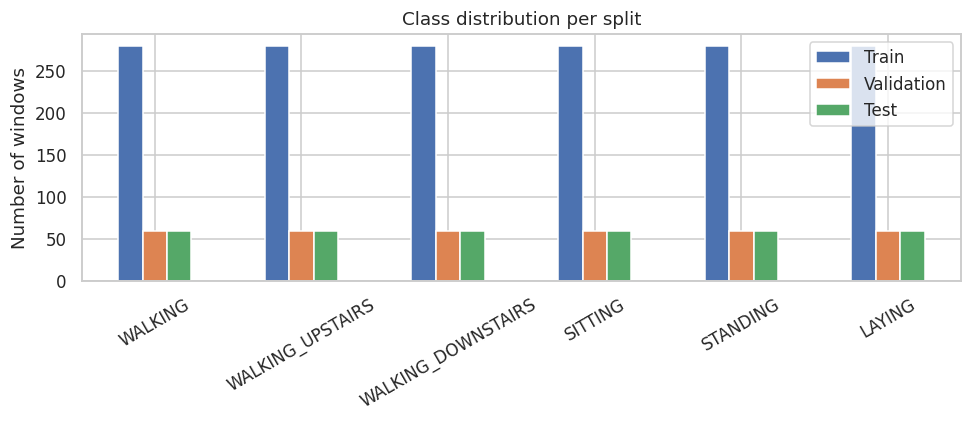

In [ ]:
# Verify the class distribution
dist = pd.DataFrame({"Train": np.bincount(y_train, minlength=6),
                     "Validation": np.bincount(y_val, minlength=6),
                     "Test": np.bincount(y_test, minlength=6)}, index=ACTIVITIES)
dist.loc["TOTAL"] = dist.sum()
display(dist)

ax = dist.iloc[:-1].plot(kind="bar", figsize=(9, 4), rot=30)
ax.set_ylabel("Number of windows"); ax.set_title("Class distribution per split")
save_show("class_distribution.png")

# Section 6 — Temporal data visualisation (Plot 1)

Representative windows from all six classes (more than the required three), three channels. We plot the **raw** signal (before normalisation) so the values keep their physical meaning.

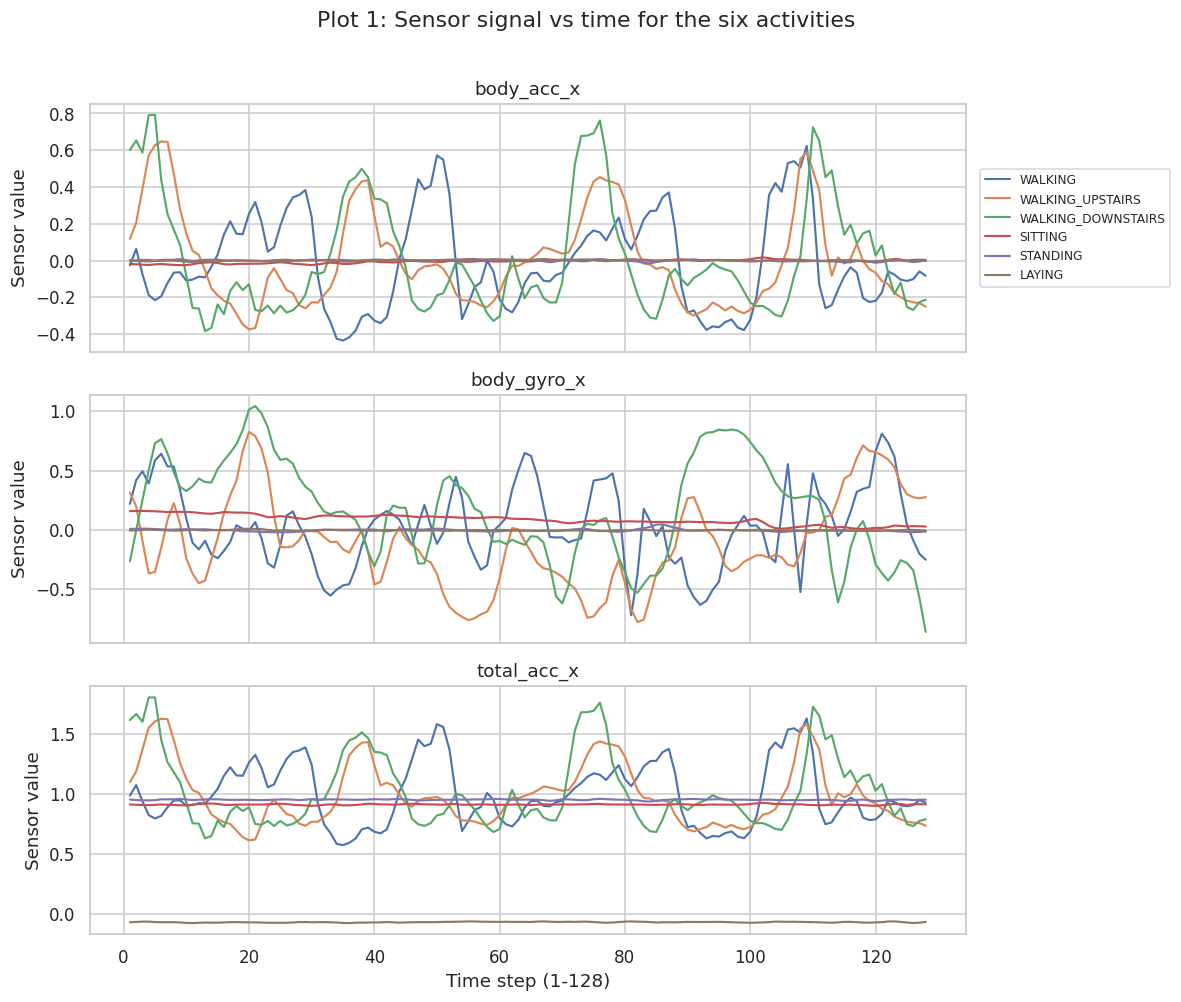

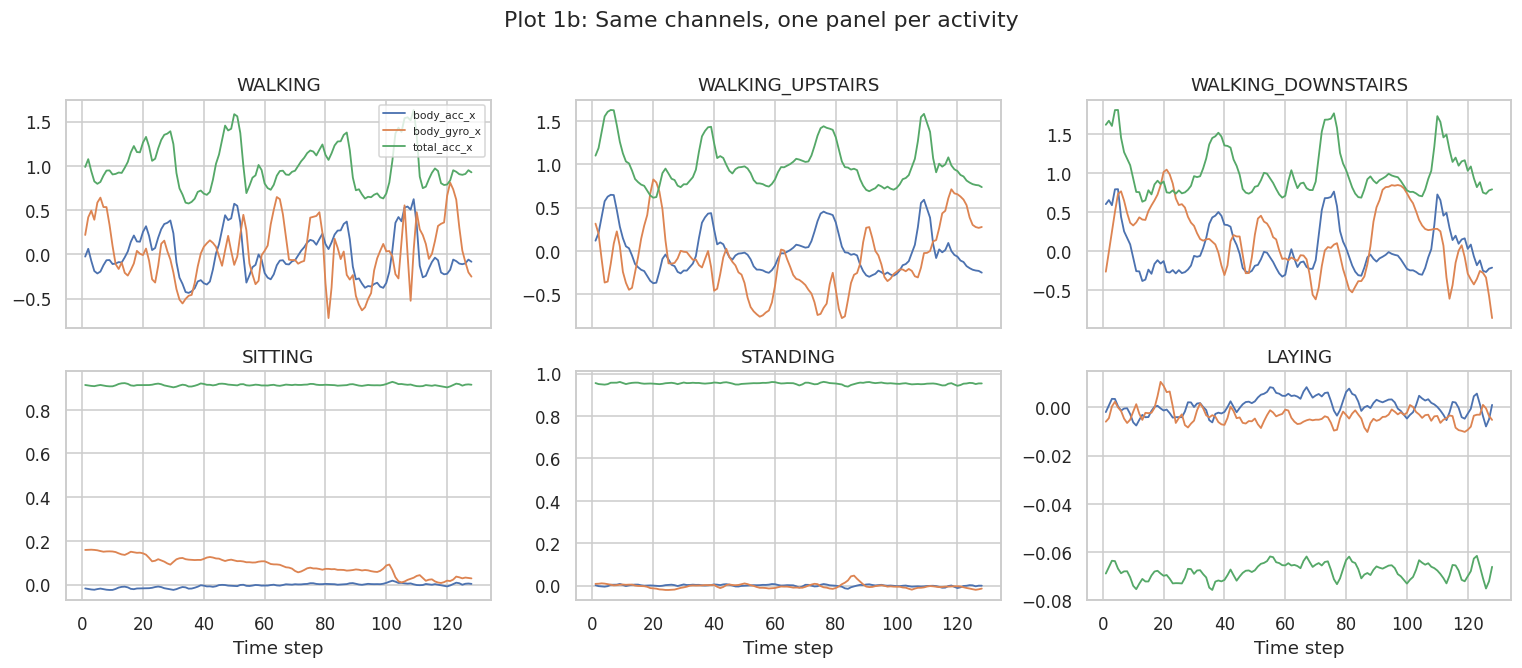

In [ ]:
plot_channels = ["body_acc_x", "body_gyro_x", "total_acc_x"]
rep = {c: int(np.where(y_train == c)[0][0]) for c in range(6)}   # first training window of each class
t = np.arange(1, SEQ_LEN + 1)

# Plot 1: sensor value vs time step, one panel per channel, one line per activity
fig, axes = plt.subplots(len(plot_channels), 1, figsize=(11, 9), sharex=True)
for ax, ch in zip(axes, plot_channels):
    ci = CHANNELS.index(ch)
    for c, i in rep.items():
        ax.plot(t, X_train_raw[i, :, ci], lw=1.4, label=ACTIVITIES[c])
    ax.set_ylabel("Sensor value"); ax.set_title(ch)
axes[-1].set_xlabel("Time step (1-128)")
axes[0].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle("Plot 1: Sensor signal vs time for the six activities", y=1.01)
save_show("plot1_sensor_signals.png")

# Plot 1b: same data, one panel per activity (easier to compare shapes)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, (c, i) in zip(axes.ravel(), rep.items()):
    for ch in plot_channels:
        ax.plot(t, X_train_raw[i, :, CHANNELS.index(ch)], lw=1.2, label=ch)
    ax.set_title(ACTIVITIES[c])
for ax in axes[-1]: ax.set_xlabel("Time step")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Plot 1b: Same channels, one panel per activity", y=1.01)
save_show("plot1b_signals_per_activity.png")

In [ ]:
# Numbers behind the picture: per-activity signal "energy" (mean within-window std) and orientation (mean total_acc)
feat = {}
for c in range(6):
    W = X_train_raw[y_train == c]                                   # (n_c, 128, 9)
    row = {f"std({ch})": W[:, :, i].std(axis=1).mean() for i, ch in enumerate(CHANNELS)}
    row.update({f"mean({ch})": W[:, :, CHANNELS.index(ch)].mean() for ch in ["total_acc_x", "total_acc_y", "total_acc_z"]})
    feat[ACTIVITIES[c]] = row
feat = pd.DataFrame(feat).T
display(feat[[f"std({ch})" for ch in CHANNELS]])

motion = feat[["std(body_acc_x)", "std(body_acc_y)", "std(body_acc_z)"]].mean(axis=1).sort_values(ascending=False)
print("Motion energy (mean std of body acceleration), high -> low:")
print(motion.round(4).to_string())

z = (feat - feat.mean()) / (feat.std() + 1e-9)                      # standardise columns, then compare activities
pairs = sorted(((np.linalg.norm(z.loc[a] - z.loc[b]), a, b) for a, b in itertools.combinations(z.index, 2)))
print("\nMost similar activity pairs (smaller distance = more similar signals):")
for d, a, b in pairs[:3]:
    print(f"  {a:20s} vs {b:20s}  distance = {d:.2f}")

dynamic, static = list(motion.index[:3]), list(motion.index[3:])
inference("Temporal pattern in the sensor signals (Plot 1)",
          what=f"Raw sensor value against time step (1-128) for {len(plot_channels)} channels ({', '.join(plot_channels)}) and one example window from each of the six activities.",
          trend=f"The activities with the highest motion energy are {', '.join(dynamic)}: their body-acceleration and gyroscope traces oscillate repeatedly across the window. {', '.join(static)} are almost flat, with tiny body-acceleration variation. The closest pairs by signal statistics are "
                + "; ".join(f"{a} / {b}" for _, a, b in pairs[:2]) + ".",
          why="Walking-type activities are periodic (each step repeats the pattern), so the signal has rhythm. Static postures have no rhythm, and they differ mainly in the constant gravity component of total acceleration (device orientation), not in the oscillation. Similar-looking activities are hard to separate. Order matters because the rhythm (peaks, spacing, direction of change) exists only in the time sequence; shuffling the time steps would destroy it.",
          conclusion="Activity information is carried by the temporal pattern (rhythm, amplitude, orientation over time), which motivates a model that reads the 128 steps in order, i.e. a recurrent network.")

,std(body_acc_x),std(body_acc_y),std(body_acc_z),std(body_gyro_x),std(body_gyro_y),std(body_gyro_z),std(total_acc_x),std(total_acc_y),std(total_acc_z)
WALKING,0.2235,0.1689,0.1382,0.4681,0.5167,0.3314,0.2231,0.1681,0.1368
WALKING_UPSTAIRS,0.2527,0.1702,0.1569,0.4512,0.5121,0.3717,0.2518,0.1671,0.1522
WALKING_DOWNSTAIRS,0.3689,0.1840,0.1524,0.5880,0.5257,0.3564,0.3682,0.1823,0.1500
SITTING,0.0069,0.0140,0.0152,0.0188,0.0288,0.0226,0.0055,0.0087,0.0106
STANDING,0.0060,0.0119,0.0128,0.0426,0.0278,0.0205,0.0054,0.0100,0.0100
LAYING,0.0128,0.0096,0.0109,0.0239,0.0254,0.0171,0.0083,0.0088,0.0090


Motion energy (mean std of body acceleration), high -> low:
WALKING_DOWNSTAIRS    0.2351
WALKING_UPSTAIRS      0.1932
WALKING               0.1769
SITTING               0.0120
LAYING                0.0111
STANDING              0.0103

Most similar activity pairs (smaller distance = more similar signals):
  WALKING              vs WALKING_UPSTAIRS      distance = 0.64
  SITTING              vs STANDING              distance = 1.11
  WALKING_UPSTAIRS     vs WALKING_DOWNSTAIRS    distance = 1.31
INFERENCE - Temporal pattern in the sensor signals (Plot 1)
1. What the plot shows: Raw sensor value against time step (1-128) for 3 channels (body_acc_x,
     body_gyro_x, total_acc_x) and one example window from each of the six activities.
2. Trend observed: The activities with the highest motion energy are WALKING_DOWNSTAIRS,
     WALKING_UPSTAIRS, WALKING: their body-acceleration and gyroscope traces oscillate repeatedly across
     the window. SITTING, LAYING, STANDING are almost flat, with t

# Section 7 — Vanilla RNN architecture

At every time step the hidden state is updated:

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b_h), \qquad y_t = g(W_y h_t + b_y)$$

For sequence classification only the **final hidden state** $h_T$ goes to the classifier (Dense + softmax). The same weights $W_x, W_h, b_h$ are reused at every step (unrolled view: $x_1 \to h_1 \to x_2 \to h_2 \to \cdots \to h_T \to$ Softmax).

# Section 8 — Backpropagation Through Time (BPTT)

When the RNN is unrolled, the loss depends on the whole chain $h_1 \to h_2 \to \cdots \to h_T$. BPTT sends the error backwards along that chain, and the gradient for the shared weights is the **sum of contributions from all time steps**. The gradient that reaches an early step is a product of many Jacobians:

$$\frac{\partial h_T}{\partial h_{T-k}} = \prod_{j=T-k+1}^{T} \frac{\partial h_j}{\partial h_{j-1}} = \prod_j \mathrm{diag}\big(1-h_j^2\big)\,W_h$$

- **Vanishing gradients:** $\left\lVert \partial h_t / \partial h_{t-k} \right\rVert \to 0$ when the factors are below 1 (tanh derivative is at most 1, and $\lVert W_h \rVert$ small). Early inputs stop influencing learning.
- **Exploding gradients:** factors above 1 make the product grow exponentially. Remedy: gradient clipping.
- **Long-term dependencies** are hard to learn, and computation is **sequential** (step t needs step t−1), so there is limited parallelism.

### Numerical exercise
Given $x_1=0.5,\ x_2=0.7,\ x_3=0.2,\ h_0=0,\ W_x=0.5,\ W_h=0.8,\ b=0.1$ and $h_t=\tanh(W_x x_t + W_h h_{t-1} + b)$:

**Manual working (calculator, 4 d.p.):**

- $t=1$: $a_1 = 0.5(0.5) + 0.8(0) + 0.1 = 0.35$, so $h_1 = \tanh(0.35) \approx 0.3364$
- $t=2$: $a_2 = 0.5(0.7) + 0.8(0.3364) + 0.1 = 0.71912$, so $h_2 = \tanh(0.71912) \approx 0.6164$
- $t=3$: $a_3 = 0.5(0.2) + 0.8(0.6164) + 0.1 = 0.69312$, so $h_3 = \tanh(0.69312) \approx 0.6000$

Now verify with a NumPy loop and with an actual Keras `SimpleRNN` whose weights are set to these numbers.

In [ ]:
x_seq = [0.5, 0.7, 0.2]
Wx, Wh, b = 0.5, 0.8, 0.1
manual = [0.3364, 0.6164, 0.6000]          # your hand calculation (Section 8 working above)

# (a) plain-Python loop
h_prev, h_np = 0.0, []
for step, xt in enumerate(x_seq, start=1):
    a = Wx * xt + Wh * h_prev + b
    h_new = math.tanh(a)
    print(f"t={step}: a = {Wx}*{xt} + {Wh}*{h_prev:.4f} + {b} = {a:.5f}  ->  h{step} = tanh(a) = {h_new:.4f}")
    h_np.append(h_new); h_prev = h_new

# (b) a real Keras SimpleRNN with the same weights
rnn_check = layers.SimpleRNN(1, activation="tanh", return_sequences=True)
xin = np.array(x_seq, dtype="float32").reshape(1, 3, 1)       # (N=1, T=3, F=1)
_ = rnn_check(xin)                                            # build the layer
rnn_check.set_weights([np.array([[Wx]], "float32"), np.array([[Wh]], "float32"), np.array([b], "float32")])
h_keras = rnn_check(xin).numpy().ravel()

cmp = pd.DataFrame({"Hand calc": manual, "NumPy loop": h_np, "Keras SimpleRNN": h_keras}, index=["h1", "h2", "h3"])
cmp["|Hand - Keras|"] = (cmp["Hand calc"] - cmp["Keras SimpleRNN"]).abs()
display(cmp)
print("Hand calculation matches the program:", np.allclose(manual, h_keras, atol=1e-3))

t=1: a = 0.5*0.5 + 0.8*0.0000 + 0.1 = 0.35000  ->  h1 = tanh(a) = 0.3364
t=2: a = 0.5*0.7 + 0.8*0.3364 + 0.1 = 0.71910  ->  h2 = tanh(a) = 0.6164
t=3: a = 0.5*0.2 + 0.8*0.6164 + 0.1 = 0.69308  ->  h3 = tanh(a) = 0.6000


,Hand calc,NumPy loop,Keras SimpleRNN,|Hand - Keras|
h1,0.3364,0.3364,0.3364,2.4465e-05
h2,0.6164,0.6164,0.6164,4.8217e-05
h3,0.6000,0.6000,0.6000,4.2057e-05


Hand calculation matches the program: True


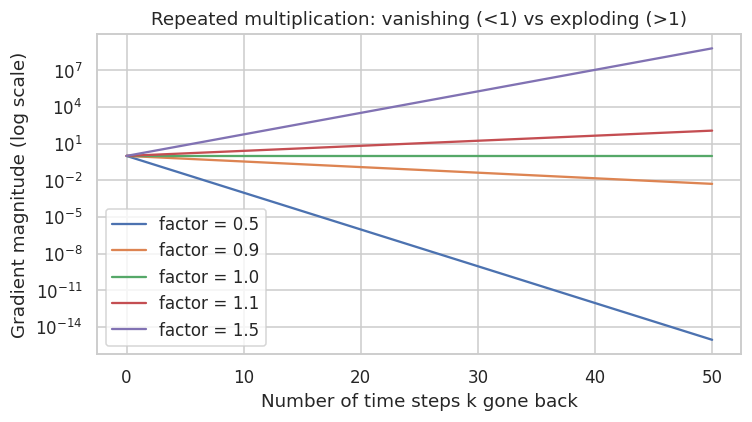

0.5^50 = 8.88e-16   |   1.5^50 = 6.38e+08


In [ ]:
# Why gradients vanish / explode: a product of k identical factors w behaves like w**k
k = np.arange(0, 51)
plt.figure(figsize=(7, 4))
for w in [0.5, 0.9, 1.0, 1.1, 1.5]:
    plt.semilogy(k, np.power(w, k), label=f"factor = {w}")
plt.xlabel("Number of time steps k gone back"); plt.ylabel("Gradient magnitude (log scale)")
plt.title("Repeated multiplication: vanishing (<1) vs exploding (>1)")
plt.legend()
save_show("bptt_vanishing_exploding.png")
print(f"0.5^50 = {0.5**50:.2e}   |   1.5^50 = {1.5**50:.2e}")

# Section 9 — RNN implementation

Architecture: `Input(128×9) → SimpleRNN(32) → Dropout(0.2) → Dense(16, ReLU) → Dense(6, Softmax)`.

Training config: Adam, lr = 1e-3, batch 32, 30 epochs, sparse categorical cross-entropy. The **same** builder, data, optimizer, batch size and evaluation function are reused for LSTM and GRU (Section 12), and only the recurrent layer changes.

In [ ]:
REC = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}

def build_model(cell="RNN", units=UNITS, seq_len=SEQ_LEN, n_features=N_FEATURES, n_classes=N_CLASSES,
                dropout=DROPOUT, second_layer=False, bidirectional=False, name=None):
    """Input -> [recurrent] -> Dropout -> Dense(16, relu) -> Dense(6, softmax).
       second_layer / bidirectional are only used by the additional exercises (Section 28)."""
    Rec = REC[cell]
    inp = keras.Input(shape=(seq_len, n_features))
    x = inp
    if second_layer:
        x = Rec(units, return_sequences=True)(x)
    rec = Rec(units)
    x = layers.Bidirectional(rec)(x) if bidirectional else rec(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(16, activation="relu")(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out, name=name or f"{cell}_{units}u")

class EpochPrinter(keras.callbacks.Callback):
    """Prints a short progress line every few epochs instead of 30 lines per model."""
    def __init__(self, every=5): super().__init__(); self.every = every
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % self.every == 0:
            print(f"   epoch {epoch+1:02d} | loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f} | "
                  f"val_loss {logs['val_loss']:.4f}  val_acc {logs['val_accuracy']:.4f}")

def train_and_eval(cell, Xtr, ytr, Xva, yva, Xte, yte, units=UNITS, epochs=EPOCHS, **kw):
    """Trains one model with the fixed protocol and evaluates it on the test set."""
    set_seed()
    model = build_model(cell, units=units, seq_len=Xtr.shape[1], **kw)
    model.compile(optimizer=keras.optimizers.Adam(LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=BATCH_SIZE,
                     verbose=0, callbacks=[EpochPrinter()])
    train_time = time.time() - t0
    y_prob = model.predict(Xte, verbose=0)
    y_pred = y_prob.argmax(axis=1)
    p, r, f, _ = precision_recall_fscore_support(yte, y_pred, average="macro", zero_division=0)
    return dict(model=model, history=hist.history, time=train_time,
                params=int(sum(np.prod(w.shape) for w in model.trainable_weights)),
                acc=accuracy_score(yte, y_pred), precision=p, recall=r, f1=f,
                y_pred=y_pred, cm=confusion_matrix(yte, y_pred, labels=range(N_CLASSES)))

# one throw-away run so that one-time GPU start-up cost is not charged to the first model's training time
_w = build_model("LSTM"); _w.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
_w.fit(X_train[:64], y_train[:64], epochs=1, verbose=0); del _w

results = {}
print("=== RNN ===")
results["RNN"] = train_and_eval("RNN", X_train, y_train, X_val, y_val, X_test, y_test)
results["RNN"]["model"].summary()
print(f"Training time: {results['RNN']['time']:.1f} s | Test accuracy: {results['RNN']['acc']*100:.2f}%")

=== RNN ===
   epoch 01 | loss 1.6579  acc 0.3607 | val_loss 1.5055  val_acc 0.4556
   epoch 05 | loss 1.0665  acc 0.5887 | val_loss 0.9851  val_acc 0.6028
   epoch 10 | loss 0.7365  acc 0.6756 | val_loss 0.7223  val_acc 0.6500
   epoch 15 | loss 0.6321  acc 0.7262 | val_loss 0.5895  val_acc 0.7278
   epoch 20 | loss 0.5518  acc 0.7750 | val_loss 0.5276  val_acc 0.7639
   epoch 25 | loss 0.4364  acc 0.8262 | val_loss 0.4277  val_acc 0.8111
   epoch 30 | loss 0.3900  acc 0.8542 | val_loss 0.4255  val_acc 0.8111


Model: "RNN_32u"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 9)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,924 (23.14 KB)

 Trainable params: 1,974 (7.71 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,950 (15.43 KB)

Training time: 24.4 s | Test accuracy: 84.17%


# Section 10 — LSTM architecture

LSTM adds a **cell state** $C_t$ (long-term memory) and three gates:

$$f_t=\sigma(W_f[h_{t-1},x_t]+b_f),\quad i_t=\sigma(W_i[h_{t-1},x_t]+b_i),\quad o_t=\sigma(W_o[h_{t-1},x_t]+b_o)$$
$$\tilde C_t=\tanh(W_C[h_{t-1},x_t]+b_C),\quad C_t=f_t\odot C_{t-1}+i_t\odot\tilde C_t,\quad h_t=o_t\odot\tanh(C_t)$$

**Required inference: how the cell state and gates retain or discard information.**
The cell state is a memory line that runs through time and is updated by *addition*: $C_t = f_t \odot C_{t-1} + i_t \odot \tilde C_t$. The **forget gate** $f_t$ (0 to 1) scales the old memory: near 1 keeps it, near 0 erases it. The **input gate** $i_t$ decides how much of the new candidate $\tilde C_t$ is written. The **output gate** $o_t$ decides how much of the memory is exposed as $h_t$. Because the memory is carried forward by an element-wise multiply by $f_t$ (not by repeatedly passing through a squashing matrix), gradients can flow back along $C_t$ over many steps without shrinking much when $f_t \approx 1$. That is why the LSTM can hold useful information over long sequences and drop what is irrelevant.

# Section 11 — GRU architecture

$$z_t=\sigma(W_z[h_{t-1},x_t]+b_z),\quad r_t=\sigma(W_r[h_{t-1},x_t]+b_r)$$
$$\tilde h_t=\tanh(W_h[r_t\odot h_{t-1},x_t]+b_h),\quad h_t=(1-z_t)\,h_{t-1}+z_t\,\tilde h_t$$

The **update gate** $z_t$ blends old state and new candidate (it plays the role of LSTM's forget and input gates combined). The **reset gate** $r_t$ decides how much of the previous state is used to build the candidate. There is **no separate cell state**: $h_t$ is both the memory and the output.

| | Gates | Memory representation |
|---|---|---|
| RNN | none | hidden state $h_t$ only |
| LSTM | forget, input, output (3) | hidden state $h_t$ **and** cell state $C_t$ |
| GRU | update, reset (2) | hidden state $h_t$ only |

# Section 12 — LSTM and GRU implementation

Same classifier as Section 9. **Only the recurrent layer is replaced** (32 units, 6 classes each).

In [ ]:
for cell in ["LSTM", "GRU"]:
    print(f"=== {cell} ===")
    results[cell] = train_and_eval(cell, X_train, y_train, X_val, y_val, X_test, y_test)
    results[cell]["model"].summary()
    print(f"Training time: {results[cell]['time']:.1f} s | Test accuracy: {results[cell]['acc']*100:.2f}%\n")

=== LSTM ===
   epoch 01 | loss 1.6405  acc 0.3655 | val_loss 1.4591  val_acc 0.3722
   epoch 05 | loss 0.7929  acc 0.6929 | val_loss 0.7370  val_acc 0.7167
   epoch 10 | loss 0.5922  acc 0.7756 | val_loss 0.4499  val_acc 0.8250
   epoch 15 | loss 0.3478  acc 0.8530 | val_loss 0.3522  val_acc 0.8722
   epoch 20 | loss 0.3226  acc 0.8774 | val_loss 0.3195  val_acc 0.8861
   epoch 25 | loss 0.2216  acc 0.9208 | val_loss 0.2211  val_acc 0.9194
   epoch 30 | loss 0.1732  acc 0.9470 | val_loss 0.1959  val_acc 0.9278


Model: "LSTM_32u"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 9)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         5,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,020 (70.39 KB)

 Trainable params: 6,006 (23.46 KB)

...

 Total params: 14,276 (55.77 KB)

 Trainable params: 4,758 (18.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,518 (37.18 KB)

Training time: 20.3 s | Test accuracy: 95.56%



In [ ]:
# Sanity check: where the parameter counts come from (F = 9 inputs, U = 32 units)
F, U = N_FEATURES, UNITS
formula = {"RNN":  F*U + U*U + U,            # 1 block: W_x, W_h, b
           "LSTM": 4 * (F*U + U*U + U),      # 4 blocks: forget, input, candidate, output
           "GRU":  3 * (F*U + U*U + 2*U)}    # 3 blocks: update, reset, candidate (Keras reset_after=True -> 2 biases)
head = U*16 + 16 + 16*N_CLASSES + N_CLASSES  # Dense(16) + Dense(6)
chk = pd.DataFrame({"Recurrent layer (formula)": formula,
                    "+ Dense head": head,
                    "Total (formula)": {k: v + head for k, v in formula.items()},
                    "Total (Keras)": {k: results[k]["params"] for k in results}})
display(chk)

,Recurrent layer (formula),+ Dense head,Total (formula),Total (Keras)
RNN,1344,630,1974,1974
LSTM,5376,630,6006,6006
GRU,4128,630,4758,4758


# Section 13 — Training curves (Plots 2 and 3)

For each model: **Plot 2** training vs validation loss, **Plot 3** training vs validation accuracy (%). The cell after the plots computes the numbers you need to talk about convergence, overfitting, underfitting and the generalisation gap.

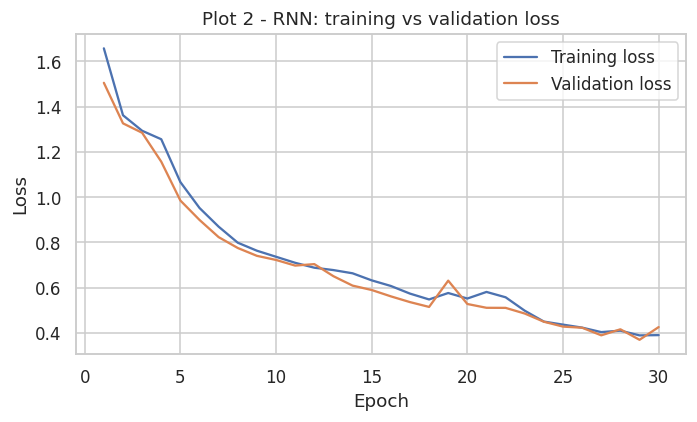

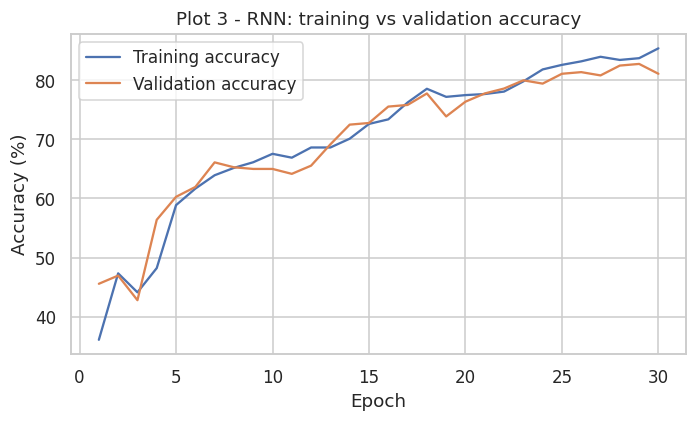

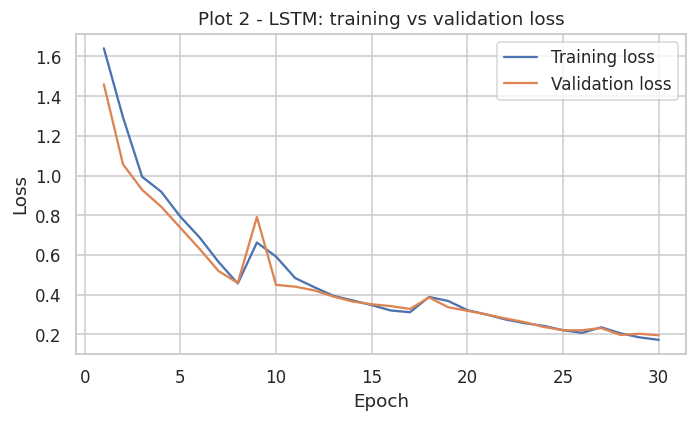

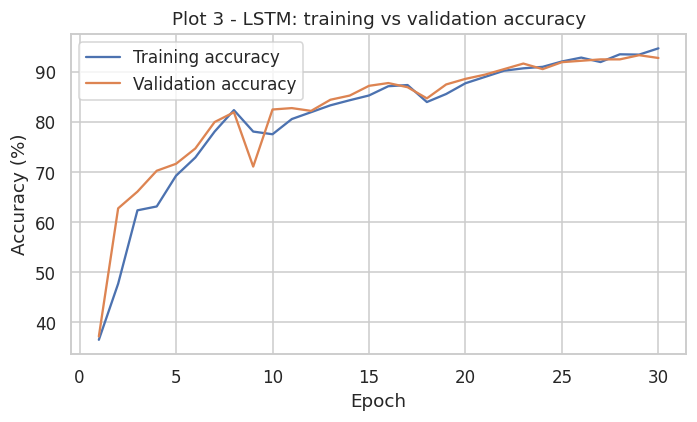

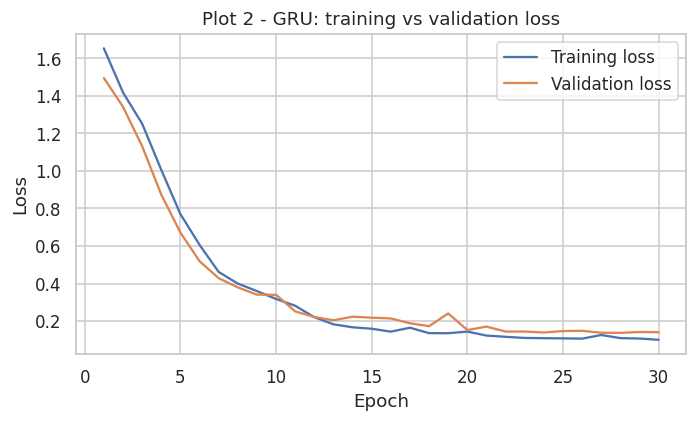

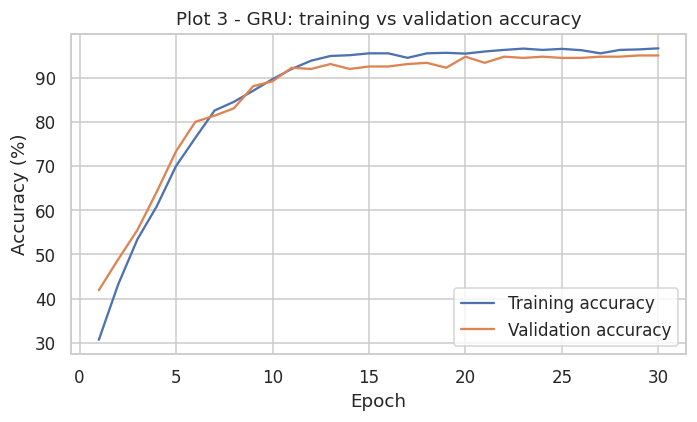

In [ ]:
def plot_curves(name, h):
    ep = np.arange(1, len(h["loss"]) + 1)
    plt.figure(figsize=(6.5, 4))
    plt.plot(ep, h["loss"], label="Training loss"); plt.plot(ep, h["val_loss"], label="Validation loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"Plot 2 - {name}: training vs validation loss"); plt.legend()
    save_show(f"plot2_loss_{name}.png")

    plt.figure(figsize=(6.5, 4))
    plt.plot(ep, np.array(h["accuracy"]) * 100, label="Training accuracy")
    plt.plot(ep, np.array(h["val_accuracy"]) * 100, label="Validation accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.title(f"Plot 3 - {name}: training vs validation accuracy"); plt.legend()
    save_show(f"plot3_accuracy_{name}.png")

for name in ["RNN", "LSTM", "GRU"]:
    plot_curves(name, results[name]["history"])

In [ ]:
def diagnose(h):
    """Numbers used to judge convergence / over-fitting / under-fitting (thresholds are simple rules of thumb)."""
    tl, vl = np.array(h["loss"]), np.array(h["val_loss"])
    ta, va = np.array(h["accuracy"]) * 100, np.array(h["val_accuracy"]) * 100
    E = len(tl)
    d = dict(epochs=E, final_train_loss=tl[-1], final_val_loss=vl[-1], final_train_acc=ta[-1], final_val_acc=va[-1],
             best_val_loss=vl.min(), best_epoch=int(vl.argmin()) + 1, gap=ta[-1] - va[-1],
             loss_rise=(vl[-1] - vl.min()) / vl.min() * 100,
             ep90=next((i + 1 for i, v in enumerate(va) if v >= 90), None),
             max_val_acc=va.max())
    d["stable"] = None if E < 10 else abs(vl[-5:].mean() - vl[-10:-5].mean()) / vl[-10:-5].mean() < 0.05
    d["overfit"] = (d["gap"] > 5) and (d["loss_rise"] > 10)
    d["underfit"] = d["final_train_acc"] < 80
    return d

diag = {m: diagnose(results[m]["history"]) for m in ["RNN", "LSTM", "GRU"]}
display(pd.DataFrame(diag).T[["best_epoch", "best_val_loss", "final_train_loss", "final_val_loss",
                              "final_train_acc", "final_val_acc", "gap", "loss_rise", "ep90", "stable", "overfit", "underfit"]])

WHY = {"RNN": "a vanilla RNN squeezes everything through one tanh state, so gradients shrink over 128 steps (BPTT) and learning is slower or noisier",
       "LSTM": "the gated cell state gives gradients a more direct path back in time, which usually makes optimisation smoother but costs more parameters",
       "GRU": "the two-gate update gives a similar direct path with fewer parameters, so it often converges about as fast as LSTM"}
for m in ["RNN", "LSTM", "GRU"]:
    d = diag[m]
    ep90 = f"first reaches 90% validation accuracy at epoch {d['ep90']}" if d["ep90"] else "never reaches 90% validation accuracy"
    stab = "not enough epochs to judge stability" if d["stable"] is None else ("validation loss is flat over the last epochs (converged)" if d["stable"] else "validation loss is still changing at the end (not fully converged)")
    inference(f"Convergence behaviour of {m} (Plots 2 and 3)",
              what=f"Training and validation loss/accuracy of {m} over {d['epochs']} epochs.",
              trend=f"Validation loss is lowest at epoch {d['best_epoch']} ({d['best_val_loss']:.3f}) and ends at {d['final_val_loss']:.3f}. The model {ep90}. Final training / validation accuracy = {d['final_train_acc']:.1f}% / {d['final_val_acc']:.1f}% (gap {d['gap']:+.1f} points); {stab}.",
              why=f"Possible reason: {WHY[m]}.",
              conclusion=f"{m} reaches a best validation accuracy of {d['max_val_acc']:.1f}%.")

print("Rule of thumb used: OVERFITTING if train-val accuracy gap > 5 points AND final val loss > 10% above its minimum;")
print("UNDERFITTING if final training accuracy < 80%. Always confirm by looking at the plots.\n")
for m in ["RNN", "LSTM", "GRU"]:
    d = diag[m]
    verdict = "overfitting" if d["overfit"] else ("underfitting" if d["underfit"] else "neither clear overfitting nor underfitting")
    print(f"{m}: {verdict} | generalisation gap (train acc - val acc) = {d['gap']:+.1f} points")

,best_epoch,best_val_loss,final_train_loss,final_val_loss,final_train_acc,final_val_acc,gap,loss_rise,ep90,stable,overfit,underfit
RNN,29,0.3693,0.39,0.4255,85.4167,81.1111,4.3056,15.2173,None,False,False,False
LSTM,30,0.1959,0.1732,0.1959,94.7024,92.7778,1.9246,0.0,22,False,False,False
GRU,28,0.1373,0.1003,0.1405,96.6071,95.0,1.6071,2.3598,11,False,False,False


INFERENCE - Convergence behaviour of RNN (Plots 2 and 3)
1. What the plot shows: Training and validation loss/accuracy of RNN over 30 epochs.
2. Trend observed: Validation loss is lowest at epoch 29 (0.369) and ends at 0.426. The model never
     reaches 90% validation accuracy. Final training / validation accuracy = 85.4% / 81.1% (gap +4.3
     points); validation loss is still changing at the end (not fully converged).
3. Why it may occur: Possible reason: a vanilla RNN squeezes everything through one tanh state, so
     gradients shrink over 128 steps (BPTT) and learning is slower or noisier.
4. Conclusion: RNN reaches a best validation accuracy of 82.8%.

INFERENCE - Convergence behaviour of LSTM (Plots 2 and 3)
1. What the plot shows: Training and validation loss/accuracy of LSTM over 30 epochs.
2. Trend observed: Validation loss is lowest at epoch 30 (0.196) and ends at 0.196. The model first
     reaches 90% validation accuracy at epoch 22. Final training / validation accuracy =

# Section 14 — Performance evaluation on the independent test set

Mandatory metrics: accuracy, **macro** precision, macro recall, macro F1, confusion matrix, number of trainable parameters, training time. The test set was used only here (never for model selection).

In [ ]:
names = ["RNN", "LSTM", "GRU"]
results_table = pd.DataFrame({
    "Accuracy (%)":        [results[m]["acc"] * 100 for m in names],
    "Macro Precision (%)": [results[m]["precision"] * 100 for m in names],
    "Macro Recall (%)":    [results[m]["recall"] * 100 for m in names],
    "Macro F1 (%)":        [results[m]["f1"] * 100 for m in names],
    "Parameters":          [results[m]["params"] for m in names],
    "Training Time (s)":   [results[m]["time"] for m in names]}, index=names).T
display(results_table)
results_table.to_csv(os.path.join(FIG_DIR, "table_section14_metrics.csv"))

for m in names:
    print(f"\n---------- {m}: per-class report (test set) ----------")
    print(classification_report(y_test, results[m]["y_pred"], target_names=ACTIVITIES, digits=4, zero_division=0))

,RNN,LSTM,GRU
Accuracy (%),84.1667,93.0556,95.5556
Macro Precision (%),84.5164,93.2126,95.7768
Macro Recall (%),84.1667,93.0556,95.5556
Macro F1 (%),84.2334,93.0183,95.5357
Parameters,1974.0000,6006.0000,4758.0000
Training Time (s),24.4303,22.8452,20.2839



---------- RNN: per-class report (test set) ----------
                    precision    recall  f1-score   support

           WALKING     0.6866    0.7667    0.7244        60
  WALKING_UPSTAIRS     0.7273    0.6667    0.6957        60
WALKING_DOWNSTAIRS     1.0000    0.9500    0.9744        60
           SITTING     0.8000    0.8667    0.8320        60
          STANDING     0.8571    0.8000    0.8276        60
            LAYING     1.0000    1.0000    1.0000        60

          accuracy                         0.8417       360
         macro avg     0.8452    0.8417    0.8423       360
      weighted avg     0.8452    0.8417    0.8423       360


---------- LSTM: per-class report (test set) ----------
                    precision    recall  f1-score   support

           WALKING     0.9636    0.8833    0.9217        60
  WALKING_UPSTAIRS     0.9206    0.9667    0.9431        60
WALKING_DOWNSTAIRS     0.9677    1.0000    0.9836        60
           SITTING     0.8333    0.9167    

# Section 15 — Confusion matrix analysis (Plot 4)

One matrix per model. Rows = true activity, columns = predicted activity. The analysis cell below reads **your** matrices and reports: highest recognition rate, most misclassified activity, most confused pairs, and whether the models agree.

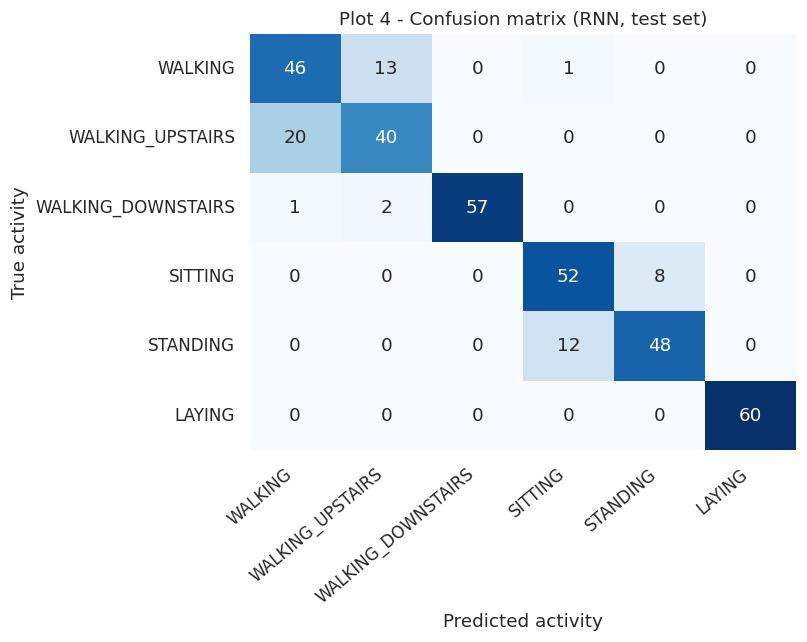

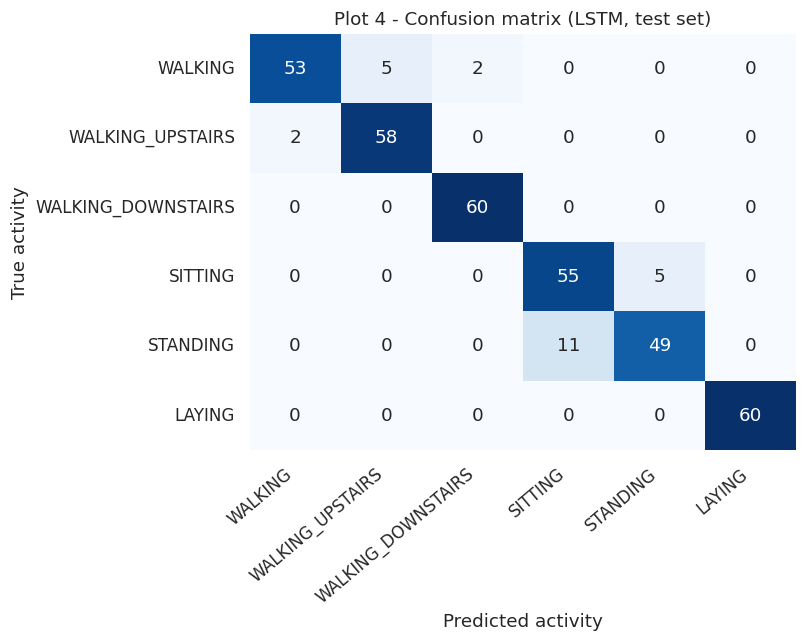

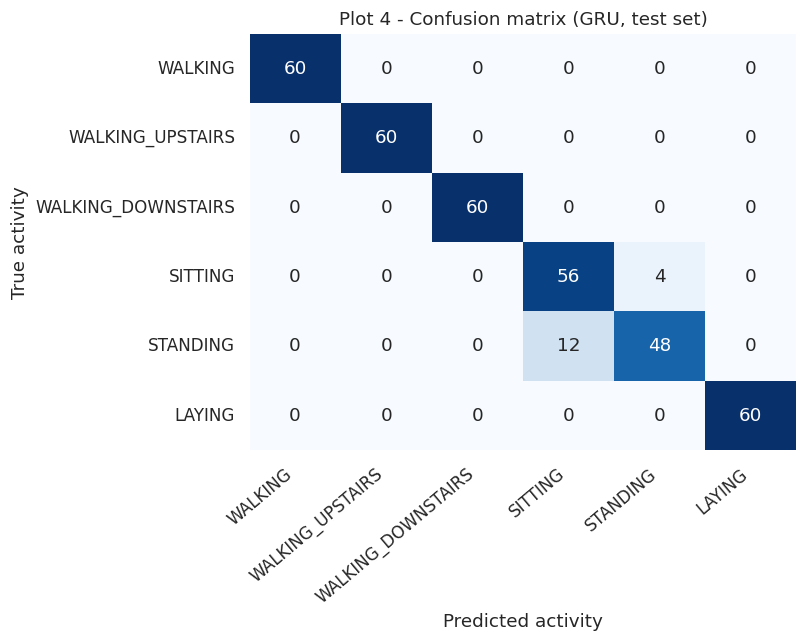

In [ ]:
def plot_cm(name, cm):
    plt.figure(figsize=(7.5, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ACTIVITIES, yticklabels=ACTIVITIES, cbar=False)
    plt.xlabel("Predicted activity"); plt.ylabel("True activity")
    plt.title(f"Plot 4 - Confusion matrix ({name}, test set)")
    plt.xticks(rotation=40, ha="right")
    save_show(f"plot4_confusion_{name}.png")

for m in names:
    plot_cm(m, results[m]["cm"])

In [ ]:
def cm_summary(cm):
    support = cm.sum(axis=1)
    recall = cm.diagonal() / np.maximum(support, 1)
    misses = support - cm.diagonal()
    pair_err = {(ACTIVITIES[i], ACTIVITIES[j]): int(cm[i, j] + cm[j, i]) for i, j in itertools.combinations(range(N_CLASSES), 2) if cm[i, j] + cm[j, i] > 0}
    top_pairs = sorted(pair_err.items(), key=lambda kv: -kv[1])[:3]
    return dict(recall=recall, misses=misses, best=int(recall.argmax()), worst=int(misses.argmax()), top_pairs=top_pairs)

cm_info = {m: cm_summary(results[m]["cm"]) for m in names}
display(pd.DataFrame({m: cm_info[m]["recall"] * 100 for m in names}, index=ACTIVITIES).rename_axis("Per-class recall (%)"))

for m in names:
    c = cm_info[m]
    pairs_txt = "; ".join(f"{a} <-> {b} ({n} errors)" for (a, b), n in c["top_pairs"]) or "none (no errors)"
    print(f"{m:5s} | highest recognition: {ACTIVITIES[c['best']]} ({c['recall'][c['best']]*100:.1f}%) | "
          f"most misclassified: {ACTIVITIES[c['worst']]} ({c['misses'][c['worst']]} wrong) | most confused pairs: {pairs_txt}")

pair_sets = [set(p for p, _ in cm_info[m]["top_pairs"]) for m in names]
common = set.intersection(*pair_sets)
same_worst = len({cm_info[m]["worst"] for m in names}) == 1
inference("Activity-wise errors (Plot 4, confusion matrices)",
          what="Test-set confusion matrices of RNN, LSTM and GRU (rows: true activity, columns: predicted activity).",
          trend="; ".join(f"{m}: best = {ACTIVITIES[cm_info[m]['best']]}, most misclassified = {ACTIVITIES[cm_info[m]['worst']]}" for m in names)
                + f". Pairs among the top-3 confused pairs of all three models: {', '.join(f'{a} <-> {b}' for a, b in common) if common else 'none'}. "
                + ("The same activity is the most misclassified in all three models." if same_worst else "The most misclassified activity differs between models."),
          why="Activities with similar sensor patterns (for example SITTING vs STANDING, which are both static and differ only slightly in device orientation, or the three walking variants, which share the same gait rhythm) are the ones the models can mix up. Compare with the similar pairs found in Section 6.",
          conclusion="Errors are concentrated in a few similar activity pairs rather than spread evenly; " + ("they are largely consistent across the three architectures, so the difficulty comes from the data rather than one specific model." if common else "the error pattern changes with the architecture, so part of the difficulty is model-specific.") + " Accuracy alone would not show this.")

,RNN,LSTM,GRU
Per-class recall (%),,,
WALKING,76.6667,88.3333,100.0000
WALKING_UPSTAIRS,66.6667,96.6667,100.0000
WALKING_DOWNSTAIRS,95.0000,100.0000,100.0000
SITTING,86.6667,91.6667,93.3333
STANDING,80.0000,81.6667,80.0000
LAYING,100.0000,100.0000,100.0000


RNN   | highest recognition: LAYING (100.0%) | most misclassified: WALKING_UPSTAIRS (20 wrong) | most confused pairs: WALKING <-> WALKING_UPSTAIRS (33 errors); SITTING <-> STANDING (20 errors); WALKING_UPSTAIRS <-> WALKING_DOWNSTAIRS (2 errors)
LSTM  | highest recognition: WALKING_DOWNSTAIRS (100.0%) | most misclassified: STANDING (11 wrong) | most confused pairs: SITTING <-> STANDING (16 errors); WALKING <-> WALKING_UPSTAIRS (7 errors); WALKING <-> WALKING_DOWNSTAIRS (2 errors)
GRU   | highest recognition: WALKING (100.0%) | most misclassified: STANDING (12 wrong) | most confused pairs: SITTING <-> STANDING (16 errors)
INFERENCE - Activity-wise errors (Plot 4, confusion matrices)
1. What the plot shows: Test-set confusion matrices of RNN, LSTM and GRU (rows: true activity, columns:
     predicted activity).
2. Trend observed: RNN: best = LAYING, most misclassified = WALKING_UPSTAIRS; LSTM: best =
     WALKING_DOWNSTAIRS, most misclassified = STANDING; GRU: best = WALKING, most misclas

# Section 16 — RNN vs LSTM vs GRU comparison (Plot 5)

In [ ]:
prop = pd.DataFrame({"RNN":  ["Yes", "No", "No", "No", "No", "No", "No"],
                     "LSTM": ["Yes", "Yes", "Yes", "Yes", "Yes", "No", "No"],
                     "GRU":  ["Yes", "No", "No", "No", "No", "Yes", "Yes"]},
                    index=["Hidden state", "Cell state", "Forget gate", "Input gate", "Output gate", "Update gate", "Reset gate"])
measured = pd.DataFrame({m: [f"{results[m]['params']:,}", f"{results[m]['time']:.1f} s", f"{results[m]['f1']*100:.2f} %"] for m in names},
                        index=["Parameters", "Training time", "Test F1-score"])
comparison = pd.concat([prop, measured])
display(comparison)
comparison.to_csv(os.path.join(FIG_DIR, "table_section16_comparison.csv"))

,RNN,LSTM,GRU
Hidden state,Yes,Yes,Yes
Cell state,No,Yes,No
Forget gate,No,Yes,No
Input gate,No,Yes,No
Output gate,No,Yes,No
Update gate,No,No,Yes
Reset gate,No,No,Yes
Parameters,"1,974","6,006","4,758"
Training time,24.4 s,22.8 s,20.3 s
Test F1-score,84.23 %,93.02 %,95.54 %


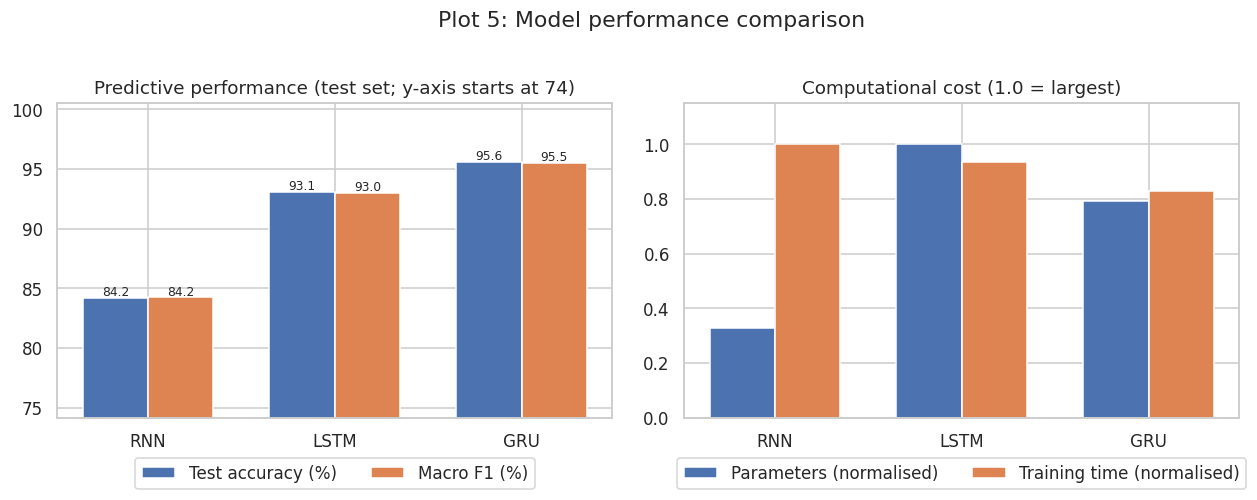

INFERENCE - Parameter and computational differences among RNN, LSTM and GRU; performance-complexity-cost trade-off (Plot 5)
1. What the plot shows: Bars compare test accuracy and macro F1 (left) and normalised parameter count and
     training time (right) for the three models.
2. Trend observed: Best macro F1: GRU (95.54%). Fewest parameters: RNN (1,974). Shortest training time:
     GRU (20.3 s). LSTM has 3.0x and GRU 2.4x the parameters of the RNN; LSTM training took 0.94x and GRU
     0.83x the RNN time.
3. Why it may occur: LSTM has four weight blocks (3 gates + candidate), GRU three, the plain RNN one, so
     parameters and arithmetic per step grow in that order. Wall-clock time also depends on the GPU
     implementation: LSTM/GRU can use fast cuDNN kernels while SimpleRNN cannot, so a smaller model is
     not always faster.
4. Conclusion: Predictive performance, model complexity and training cost pull in different directions:
     gated models cost more parameters and per-ste

In [ ]:
# Plot 5: predictive performance (left) and normalised computational cost (right, each divided by its maximum)
acc = [results[m]["acc"] * 100 for m in names]; f1 = [results[m]["f1"] * 100 for m in names]
par = np.array([results[m]["params"] for m in names], float); tim = np.array([results[m]["time"] for m in names], float)
x = np.arange(3); w = 0.35
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(x - w/2, acc, w, label="Test accuracy (%)"); axes[0].bar(x + w/2, f1, w, label="Macro F1 (%)")
lo = min(acc + f1); axes[0].set_ylim(max(0, lo - 10), 100.5)
for i, (a, b_) in enumerate(zip(acc, f1)):
    axes[0].text(i - w/2, a + 0.2, f"{a:.1f}", ha="center", fontsize=8); axes[0].text(i + w/2, b_ + 0.2, f"{b_:.1f}", ha="center", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(names); axes[0].set_title(f"Predictive performance (test set; y-axis starts at {axes[0].get_ylim()[0]:.0f})"); axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
axes[1].bar(x - w/2, par / par.max(), w, label="Parameters (normalised)"); axes[1].bar(x + w/2, tim / tim.max(), w, label="Training time (normalised)")
axes[1].set_xticks(x); axes[1].set_xticklabels(names); axes[1].set_ylim(0, 1.15); axes[1].set_title("Computational cost (1.0 = largest)"); axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.suptitle("Plot 5: Model performance comparison", y=1.02)
save_show("plot5_model_comparison.png")

best_f1 = max(names, key=lambda m: results[m]["f1"]); fastest = min(names, key=lambda m: results[m]["time"]); smallest = min(names, key=lambda m: results[m]["params"])
inference("Parameter and computational differences among RNN, LSTM and GRU; performance-complexity-cost trade-off (Plot 5)",
          what="Bars compare test accuracy and macro F1 (left) and normalised parameter count and training time (right) for the three models.",
          trend=f"Best macro F1: {best_f1} ({results[best_f1]['f1']*100:.2f}%). Fewest parameters: {smallest} ({results[smallest]['params']:,}). Shortest training time: {fastest} ({results[fastest]['time']:.1f} s). "
                f"LSTM has {results['LSTM']['params']/results['RNN']['params']:.1f}x and GRU {results['GRU']['params']/results['RNN']['params']:.1f}x the parameters of the RNN; "
                f"LSTM training took {results['LSTM']['time']/results['RNN']['time']:.2f}x and GRU {results['GRU']['time']/results['RNN']['time']:.2f}x the RNN time.",
          why="LSTM has four weight blocks (3 gates + candidate), GRU three, the plain RNN one, so parameters and arithmetic per step grow in that order. Wall-clock time also depends on the GPU implementation: LSTM/GRU can use fast cuDNN kernels while SimpleRNN cannot, so a smaller model is not always faster.",
          conclusion="Predictive performance, model complexity and training cost pull in different directions: gated models cost more parameters and per-step computation, and whether the extra capacity is worth it is judged by the F1 gain above. With this small, short-window task the differences may be small (single run, so gaps of about 1 point can be noise).")

# Section 17 — Effect of sequence length (Plot 6)

Repeat the experiment for **T ∈ {32, 64, 128}**. To keep it consistent, every shorter input is built by **truncating each window to its first T time steps**, then re-normalised with training statistics. Same split, same models, same protocol. (T = 128 reuses the main results.)

=== RNN, T = 32 ===
   epoch 01 | loss 1.6470  acc 0.3524 | val_loss 1.3746  val_acc 0.5333
   epoch 05 | loss 0.8652  acc 0.6274 | val_loss 0.8607  val_acc 0.6139
   epoch 10 | loss 0.6778  acc 0.6774 | val_loss 0.6619  val_acc 0.6778
   epoch 15 | loss 0.6369  acc 0.7214 | val_loss 0.6095  val_acc 0.6944
   epoch 20 | loss 0.5592  acc 0.7601 | val_loss 0.5469  val_acc 0.7389
   epoch 25 | loss 0.4968  acc 0.7952 | val_loss 0.4886  val_acc 0.7889
   epoch 30 | loss 0.5200  acc 0.7958 | val_loss 0.5022  val_acc 0.7750
=== LSTM, T = 32 ===
   epoch 01 | loss 1.6427  acc 0.3524 | val_loss 1.4660  val_acc 0.3833
   epoch 05 | loss 0.6635  acc 0.7387 | val_loss 0.6077  val_acc 0.7778
   epoch 10 | loss 0.3544  acc 0.8667 | val_loss 0.3858  val_acc 0.8528
   epoch 15 | loss 0.2267  acc 0.9262 | val_loss 0.2278  val_acc 0.9194
   epoch 20 | loss 0.1558  acc 0.9452 | val_loss 0.2064  val_acc 0.9278
   epoch 25 | loss 0.1088  acc 0.9613 | val_loss 0.2175  val_acc 0.9278
   epoch 30 | loss 0.14

,RNN F1 (%),LSTM F1 (%),GRU F1 (%)
Sequence Length,,,
32,74.8246,92.4570,91.3905
64,71.0221,93.9016,93.3230
128,84.2334,93.0183,95.5357


,RNN time (s),LSTM time (s),GRU time (s)
Sequence Length,,,
32,17.0478,15.1714,14.8536
64,18.2089,16.5525,16.8649
128,24.4303,22.8452,20.2839


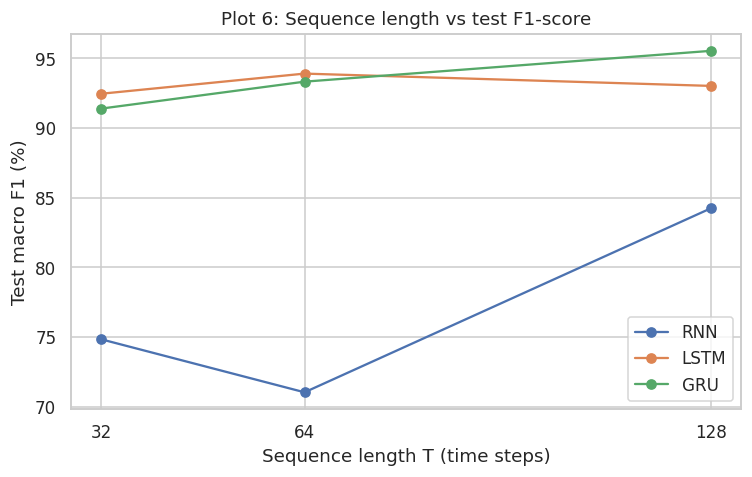

INFERENCE - Effect of sequence length (Plot 6)
1. What the plot shows: Test macro F1 of RNN, LSTM and GRU when only the first 32, 64 or 128 time steps
     of each window are used.
2. Trend observed: RNN: 74.8% (T=32) -> 71.0% (T=64) -> 84.2% (T=128), change +9.4 points; LSTM: 92.5%
     (T=32) -> 93.9% (T=64) -> 93.0% (T=128), change +0.6 points; GRU: 91.4% (T=32) -> 93.3% (T=64) ->
     95.5% (T=128), change +4.1 points.
3. Why it may occur: Short windows contain less of the movement rhythm and less orientation context, so
     activities that differ mainly in timing or amplitude are harder to separate; longer windows give
     more temporal context but cost more computation (Exercise 5 in Section 28) and give BPTT more steps
     to cross.
4. Conclusion: More temporal context improves the classification result on this dataset (mean change T=32
     to 128: +4.7 points), and the effect is larger for the plain RNN than for the gated models in this
     run.



In [ ]:
SEQ_LENS = [32, 64, 128]
seq_res = {}
for T in SEQ_LENS:
    for m in names:
        if T == SEQ_LEN:
            seq_res[(m, T)] = results[m]
        else:
            print(f"=== {m}, T = {T} ===")
            (a, b_, c), _, _ = normalize(X_train_raw[:, :T], X_val_raw[:, :T], X_test_raw[:, :T])
            seq_res[(m, T)] = train_and_eval(m, a, y_train, b_, y_val, c, y_test)

f1_tab = pd.DataFrame({f"{m} F1 (%)": [seq_res[(m, T)]["f1"] * 100 for T in SEQ_LENS] for m in names}, index=pd.Index(SEQ_LENS, name="Sequence Length"))
time_tab = pd.DataFrame({f"{m} time (s)": [seq_res[(m, T)]["time"] for T in SEQ_LENS] for m in names}, index=pd.Index(SEQ_LENS, name="Sequence Length"))
display(f1_tab); display(time_tab)
f1_tab.to_csv(os.path.join(FIG_DIR, "table_section17_seqlen_f1.csv"))

plt.figure(figsize=(7, 4.5))
for m in names:
    plt.plot(SEQ_LENS, [seq_res[(m, T)]["f1"] * 100 for T in SEQ_LENS], marker="o", label=m)
plt.xticks(SEQ_LENS); plt.xlabel("Sequence length T (time steps)"); plt.ylabel("Test macro F1 (%)")
plt.title("Plot 6: Sequence length vs test F1-score"); plt.legend()
save_show("plot6_seqlen_vs_f1.png")

gain = {m: (seq_res[(m, 128)]["f1"] - seq_res[(m, 32)]["f1"]) * 100 for m in names}
inference("Effect of sequence length (Plot 6)",
          what="Test macro F1 of RNN, LSTM and GRU when only the first 32, 64 or 128 time steps of each window are used.",
          trend="; ".join(f"{m}: {seq_res[(m,32)]['f1']*100:.1f}% (T=32) -> {seq_res[(m,64)]['f1']*100:.1f}% (T=64) -> {seq_res[(m,128)]['f1']*100:.1f}% (T=128), change {gain[m]:+.1f} points" for m in names) + ".",
          why="Short windows contain less of the movement rhythm and less orientation context, so activities that differ mainly in timing or amplitude are harder to separate; longer windows give more temporal context but cost more computation (Exercise 5 in Section 28) and give BPTT more steps to cross.",
          conclusion="More temporal context " + ("improves" if np.mean(list(gain.values())) > 0.5 else "changes little in") + " the classification result on this dataset (mean change T=32 to 128: " + f"{np.mean(list(gain.values())):+.1f} points), and the effect is " + ("larger for the plain RNN than for the gated models" if gain["RNN"] > max(gain["LSTM"], gain["GRU"]) else "not larger for the plain RNN than for the gated models") + " in this run.")

# Sections 18–19 — Video understanding: CNN + LSTM/GRU

**Pipeline:** Video → Frame extraction (10 frames, uniform) → Pretrained CNN (MobileNetV2, frozen) → Frame features (10 × D) → LSTM/GRU (32 units) → Dense softmax → Action.

Dataset: a small subset of **UCF101** (3–5 action classes, a few dozen videos per class). We want to understand the pipeline, not to beat a video-recognition benchmark.

**Class names:** UCF101 does not have classes literally called "Walking" or "Running". The closest is `WalkingWithDog`. The default classes below are `Basketball, Biking, TennisSwing, WalkingWithDog` (4 classes, all from the brief's list or its closest UCF101 equivalent). Change `VIDEO_CLASSES` if you like (any 3–5 of the 101 names).

**Video data source** (`VIDEO_SOURCE`):
- `"official"`: downloads the full `UCF101.rar` (~6.5 GB) from UCF and extracts only your chosen classes. This is the recommended one and takes a few minutes on Colab.
- `"huggingface"`: downloads a small 10-class subset (`sayakpaul/ucf101-subset`, first 10 UCF101 classes alphabetically). If your chosen classes are not in it, the notebook switches to 4 available classes and tells you.
- `"manual"`: you put `.avi` files (named like `v_Basketball_g01_c01.avi`) anywhere under `data/ucf/` yourself.

**Split:** UCF101 clips from the same *group* (`g01`…`g25`) come from one long video, so a random split would leak near-duplicate clips between train and test. We split **by group**: groups 1–4 → test, 5–7 → validation, 8–25 → train.

In [ ]:
import cv2
from tqdm.auto import tqdm

# ======================= VIDEO CONFIG =======================
VIDEO_SOURCE = "official"        # "official" | "huggingface" | "manual"
VIDEO_CLASSES = ["Basketball", "Biking", "TennisSwing", "WalkingWithDog"]   # 3-5 classes
N_FRAMES, IMG_SIZE = 10, 224
MAX_TRAIN_PER_CLASS, MAX_VAL_PER_CLASS, MAX_TEST_PER_CLASS = 40, 10, 12
VIDEO_EPOCHS, VIDEO_BATCH, VIDEO_UNITS = (5 if QUICK_TEST else 30), 8, 32
CNN_WEIGHTS = "imagenet"
VIDEO_ROOT = "data/ucf"
# ============================================================
os.makedirs(VIDEO_ROOT, exist_ok=True)

def find_videos(root):
    vids = {}
    for p in glob.glob(os.path.join(root, "**", "*.avi"), recursive=True):
        vids.setdefault(os.path.basename(p).split("_")[1], []).append(p)     # v_Basketball_g01_c01.avi -> Basketball
    return vids

def download_official(classes):
    rar = os.path.join(VIDEO_ROOT, "UCF101.rar")
    if not os.path.exists(rar):
        print("Downloading UCF101.rar (~6.5 GB) ... this can take several minutes")
        subprocess.run(["wget", "--no-check-certificate", "-q", "-O", rar, "https://www.crcv.ucf.edu/data/UCF101/UCF101.rar"], check=True)
    if shutil.which("unrar") is None:
        subprocess.run("apt-get -qq install -y unrar > /dev/null 2>&1", shell=True)
    for cls in classes:                                                        # extract only the classes we need
        subprocess.run(["unrar", "x", "-inul", "-o+", rar, f"UCF-101/{cls}/*", VIDEO_ROOT + "/"])
    if not find_videos(VIDEO_ROOT):                                            # fallback: extract everything
        print("Selective extraction found nothing; extracting the whole archive (needs ~7 GB disk) ...")
        subprocess.run(["unrar", "x", "-inul", "-o+", rar, VIDEO_ROOT + "/"])

def download_hf():
    from huggingface_hub import hf_hub_download
    import tarfile
    p = hf_hub_download(repo_id="sayakpaul/ucf101-subset", filename="UCF101_subset.tar.gz", repo_type="dataset")
    with tarfile.open(p) as tf_:
        tf_.extractall(VIDEO_ROOT)

vids = find_videos(VIDEO_ROOT)
if not all(c in vids for c in VIDEO_CLASSES):
    if VIDEO_SOURCE == "official":
        download_official(VIDEO_CLASSES)
    elif VIDEO_SOURCE == "huggingface":
        download_hf()
    vids = find_videos(VIDEO_ROOT)

available = sorted(vids)
print("Classes found on disk:", available[:15], "..." if len(available) > 15 else "")
VIDEO_CLASSES = [c for c in VIDEO_CLASSES if c in vids]
if len(VIDEO_CLASSES) < 3:
    VIDEO_CLASSES = sorted(vids, key=lambda c: -len(vids[c]))[:4]
    print("Chosen classes not available -> using these instead:", VIDEO_CLASSES)
assert len(VIDEO_CLASSES) >= 3, "Need at least 3 action classes with videos under data/ucf"
print("Video classes used:", VIDEO_CLASSES)

Classes found on disk: ['Basketball', 'Biking', 'TennisSwing', 'WalkingWithDog'] 
Video classes used: ['Basketball', 'Biking', 'TennisSwing', 'WalkingWithDog']


In [ ]:
def group_id(p): return int(os.path.basename(p).split("_")[2][1:])            # 'g07' -> 7

def pick_evenly(lst, k):
    if len(lst) <= k: return list(lst)
    return [lst[i] for i in np.linspace(0, len(lst) - 1, k).astype(int)]

def split_videos(vids, classes):
    caps = {"train": MAX_TRAIN_PER_CLASS, "val": MAX_VAL_PER_CLASS, "test": MAX_TEST_PER_CLASS}
    out = {"train": [], "val": [], "test": []}
    for ci, cls in enumerate(classes):
        files = sorted(vids[cls])
        parts = {"test":  [p for p in files if group_id(p) <= 4],
                 "val":   [p for p in files if 5 <= group_id(p) <= 7],
                 "train": [p for p in files if group_id(p) >= 8]}
        for s in out:
            out[s] += [(p, ci) for p in pick_evenly(parts[s], caps[s])]
    return out

split = split_videos(vids, VIDEO_CLASSES)
if any(len(v) < 2 * len(VIDEO_CLASSES) for v in split.values()):              # too few groups -> plain random split
    print("Not enough groups for a group-wise split; falling back to a random video-wise split.")
    rng = np.random.default_rng(SEED); split = {"train": [], "val": [], "test": []}
    for ci, cls in enumerate(VIDEO_CLASSES):
        files = sorted(vids[cls]); rng.shuffle(files)
        n = len(files); a, b_ = int(.7 * n), int(.85 * n)
        split["train"] += [(p, ci) for p in files[:a][:MAX_TRAIN_PER_CLASS]]
        split["val"]   += [(p, ci) for p in files[a:b_][:MAX_VAL_PER_CLASS]]
        split["test"]  += [(p, ci) for p in files[b_:][:MAX_TEST_PER_CLASS]]

print(pd.DataFrame({s: np.bincount([c for _, c in v], minlength=len(VIDEO_CLASSES)) for s, v in split.items()}, index=VIDEO_CLASSES).T)

       Basketball  Biking  TennisSwing  WalkingWithDog
train          40      40           40              40
val            10      10           10              10
test           12      12           12              12


# Section 20 — CNN feature extraction

Each video → 10 frames sampled **uniformly** → resized to 224×224×3 → frozen **MobileNetV2** (ImageNet weights, classification head removed, global average pooling) → one feature vector per frame. The CNN is **never trained**; features are extracted once, then the recurrent classifier is trained on them.

Note: `mobilenet_v2.preprocess_input` expects raw pixel values in [0, 255] and scales them itself, so frames are passed **without** manual normalisation (double-normalising ruins the features).

In [ ]:
def extract_frames(path, n=N_FRAMES, size=IMG_SIZE):
    """Read a video, pick n frames uniformly over its length, return (n, size, size, 3) uint8 RGB."""
    cap = cv2.VideoCapture(path); frames = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        frames.append(fr)
    cap.release()
    if len(frames) == 0: return None
    idx = np.linspace(0, len(frames) - 1, n).astype(int)
    return np.stack([cv2.resize(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB), (size, size)) for i in idx]).astype("uint8")

cnn = keras.applications.MobileNetV2(weights=CNN_WEIGHTS, include_top=False, pooling="avg", input_shape=(IMG_SIZE, IMG_SIZE, 3))
cnn.trainable = False                                     # frozen feature extractor
D = int(cnn.output.shape[-1])
print(f"MobileNetV2 (frozen): {cnn.count_params():,} parameters, all non-trainable. Feature dimension per frame D = {D}")

cache = os.path.join(VIDEO_ROOT, "feat_" + "_".join(VIDEO_CLASSES) + f"_{MAX_TRAIN_PER_CLASS}_{MAX_VAL_PER_CLASS}_{MAX_TEST_PER_CLASS}_{N_FRAMES}.npz")
if os.path.exists(cache):
    z = np.load(cache, allow_pickle=True)
    Xv = {s: z[f"X_{s}"] for s in ["train", "val", "test"]}; yv = {s: z[f"y_{s}"] for s in ["train", "val", "test"]}
    test_paths = list(z["test_paths"]); print("Loaded cached features:", cache)
else:
    Xv, yv, kept = {}, {}, {}
    for s in ["train", "val", "test"]:
        feats, labels, paths = [], [], []
        for p, ci in tqdm(split[s], desc=f"features [{s}]"):
            fr = extract_frames(p)
            if fr is None: continue
            f = cnn.predict(keras.applications.mobilenet_v2.preprocess_input(fr.astype("float32")), verbose=0)   # (10, D)
            feats.append(f); labels.append(ci); paths.append(p)
        Xv[s], yv[s], kept[s] = np.stack(feats).astype("float32"), np.array(labels), paths
    test_paths = kept["test"]
    np.savez_compressed(cache, X_train=Xv["train"], y_train=yv["train"], X_val=Xv["val"], y_val=yv["val"],
                        X_test=Xv["test"], y_test=yv["test"], test_paths=np.array(test_paths))

print("\nRequired observation:")
print(f"CNN feature dimension D = {D}")
print(f"Tensor supplied to the recurrent network: (B, {N_FRAMES}, {D})")
for s in ["train", "val", "test"]:
    print(f"  {s:5s}: X = {Xv[s].shape}, y = {yv[s].shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 (frozen): 2,257,984 parameters, all non-trainable. Feature dimension per frame D = 1280


features [train]:   0%|          | 0/160 [00:00<?, ?it/s]

features [val]:   0%|          | 0/40 [00:00<?, ?it/s]

features [test]:   0%|          | 0/48 [00:00<?, ?it/s]


Required observation:
CNN feature dimension D = 1280
Tensor supplied to the recurrent network: (B, 10, 1280)
  train: X = (160, 10, 1280), y = (160,)
  val  : X = (40, 10, 1280), y = (40,)
  test : X = (48, 10, 1280), y = (48,)


# Section 21 — CNN–LSTM / CNN–GRU model, Plots 7, 8, 9

Architecture: `Input(10 × D) → LSTM/GRU(32) → Dropout(0.3) → Dense(softmax)`. (The small dropout is our addition, because we have only a few dozen training videos.) Features are standardised with **training-set** statistics. LSTM and GRU are both trained on the identical features (Additional Exercise 6); the one with the higher **validation** accuracy is the "CNN–LSTM/GRU" used in the tables (test set not used for this choice).

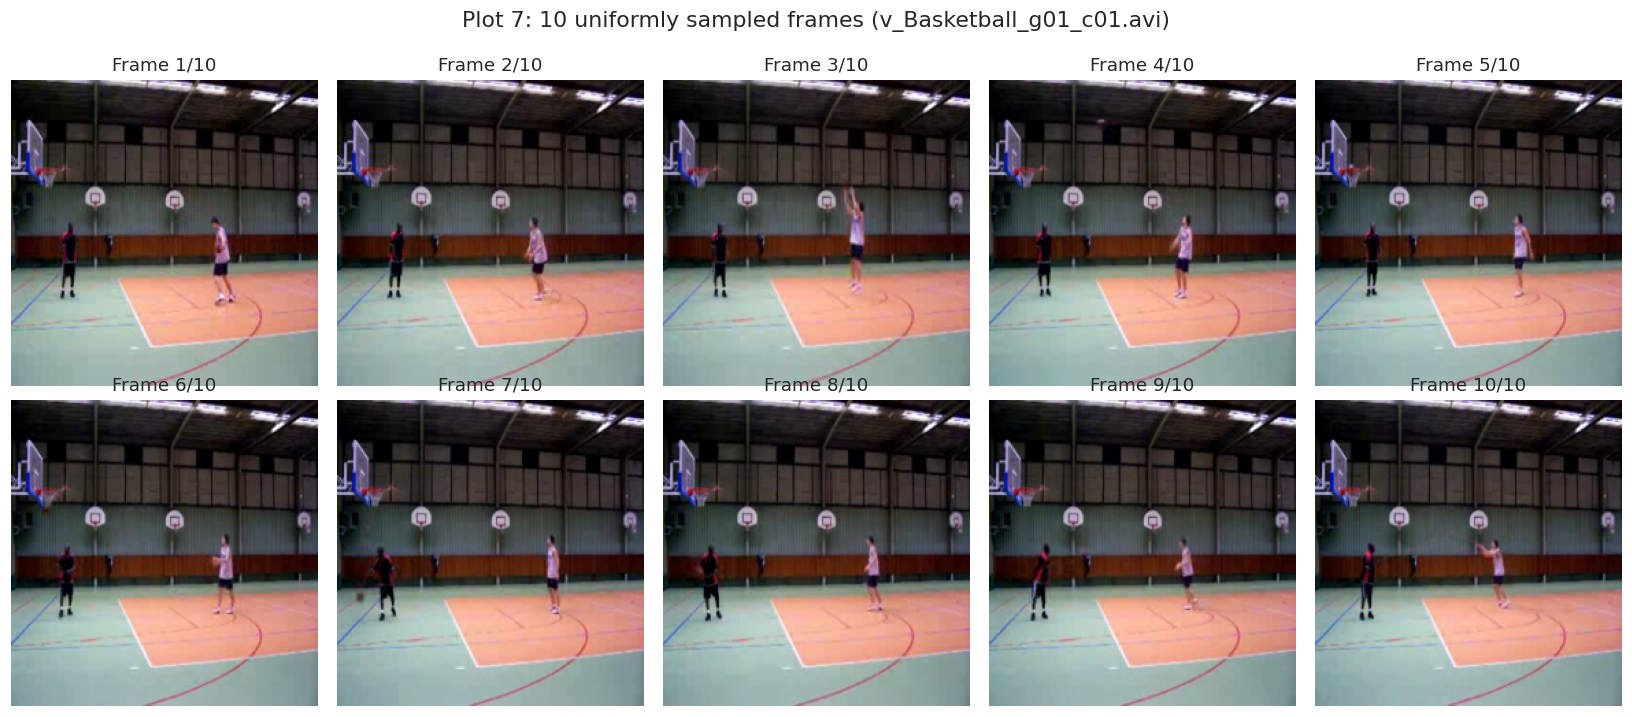

In [ ]:
# Plot 7: 10 uniformly sampled frames of one video
sample_path = test_paths[0]
frames = extract_frames(sample_path)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(frames[i]); ax.set_title(f"Frame {i+1}/{N_FRAMES}"); ax.axis("off")
fig.suptitle(f"Plot 7: 10 uniformly sampled frames ({os.path.basename(sample_path)})", y=1.0)
save_show("plot7_video_frames.png")

In [ ]:
# standardise features with TRAINING statistics
fmu, fsd = Xv["train"].mean(axis=(0, 1), keepdims=True), Xv["train"].std(axis=(0, 1), keepdims=True) + 1e-6
Xn = {s: ((Xv[s] - fmu) / fsd).astype("float32") for s in Xv}
NV = len(VIDEO_CLASSES)

def build_video_model(cell, units=VIDEO_UNITS, dropout=0.3):
    inp = keras.Input(shape=(N_FRAMES, D))
    x = REC[cell](units)(inp)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NV, activation="softmax")(x)
    return keras.Model(inp, out, name=f"CNN_{cell}")

def train_video(cell):
    set_seed()
    m = build_video_model(cell)
    m.compile(optimizer=keras.optimizers.Adam(LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = m.fit(Xn["train"], yv["train"], validation_data=(Xn["val"], yv["val"]), epochs=VIDEO_EPOCHS,
              batch_size=VIDEO_BATCH, verbose=0, callbacks=[EpochPrinter()])
    tt = time.time() - t0
    prob = m.predict(Xn["test"], verbose=0); pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(yv["test"], pred, average="macro", zero_division=0)
    return dict(model=m, history=h.history, time=tt, params=int(sum(np.prod(w.shape) for w in m.trainable_weights)),
                acc=accuracy_score(yv["test"], pred), precision=p, recall=r, f1=f, prob=prob, y_pred=pred,
                cm=confusion_matrix(yv["test"], pred, labels=range(NV)), val_acc=max(h.history["val_accuracy"]),
                val_loss=min(h.history["val_loss"]))

video_res = {}
for cell in ["LSTM", "GRU"]:
    print(f"=== CNN-{cell} ===")
    video_res[cell] = train_video(cell)
    print(f"   test accuracy {video_res[cell]['acc']*100:.2f}% | macro F1 {video_res[cell]['f1']*100:.2f}% | params {video_res[cell]['params']:,} | time {video_res[cell]['time']:.1f}s")

best_v = max(video_res, key=lambda c: (video_res[c]["val_acc"], -video_res[c]["val_loss"]))   # chosen on VALIDATION only
print(f"\nSelected recurrent model for the video task (best validation accuracy): CNN-{best_v}")
video_res[best_v]["model"].summary()

=== CNN-LSTM ===
   epoch 01 | loss 0.8864  acc 0.7125 | val_loss 0.6234  val_acc 0.8250
   epoch 05 | loss 0.0916  acc 1.0000 | val_loss 0.3261  val_acc 0.9000
   epoch 10 | loss 0.0313  acc 1.0000 | val_loss 0.2633  val_acc 0.9000
   epoch 15 | loss 0.0169  acc 1.0000 | val_loss 0.2328  val_acc 0.8750
   epoch 20 | loss 0.0130  acc 1.0000 | val_loss 0.2205  val_acc 0.8750
   epoch 25 | loss 0.0091  acc 1.0000 | val_loss 0.2131  val_acc 0.8750
   epoch 30 | loss 0.0084  acc 1.0000 | val_loss 0.2058  val_acc 0.8750
   test accuracy 85.42% | macro F1 84.84% | params 168,196 | time 7.8s
=== CNN-GRU ===
   epoch 01 | loss 0.8629  acc 0.6625 | val_loss 0.4746  val_acc 0.8750
   epoch 05 | loss 0.0462  acc 1.0000 | val_loss 0.3011  val_acc 0.9000
   epoch 10 | loss 0.0145  acc 1.0000 | val_loss 0.2848  val_acc 0.9000
   epoch 15 | loss 0.0099  acc 1.0000 | val_loss 0.2603  val_acc 0.9000
   epoch 20 | loss 0.0088  acc 1.0000 | val_loss 0.2593  val_acc 0.9000
   epoch 25 | loss 0.0054  acc 1

   epoch 30 | loss 0.0042  acc 1.0000 | val_loss 0.2448  val_acc 0.9000
   test accuracy 91.67% | macro F1 91.59% | params 126,276 | time 6.6s

Selected recurrent model for the video task (best validation accuracy): CNN-LSTM


Model: "CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 10, 1280)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 32)             │       168,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 504,590 (1.92 MB)

 Trainable params: 168,196 (657.02 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 336,394 (1.28 MB)

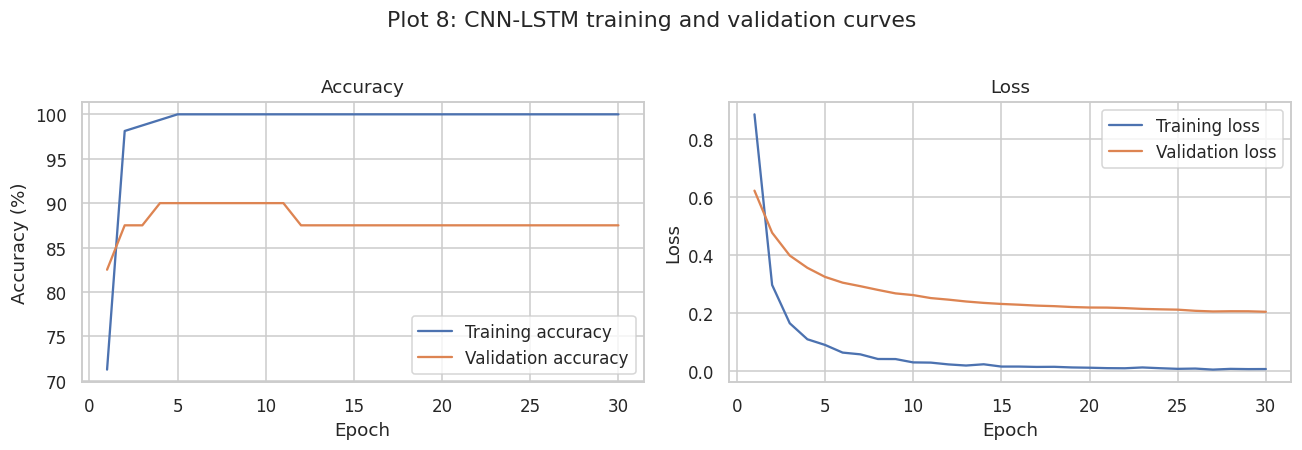

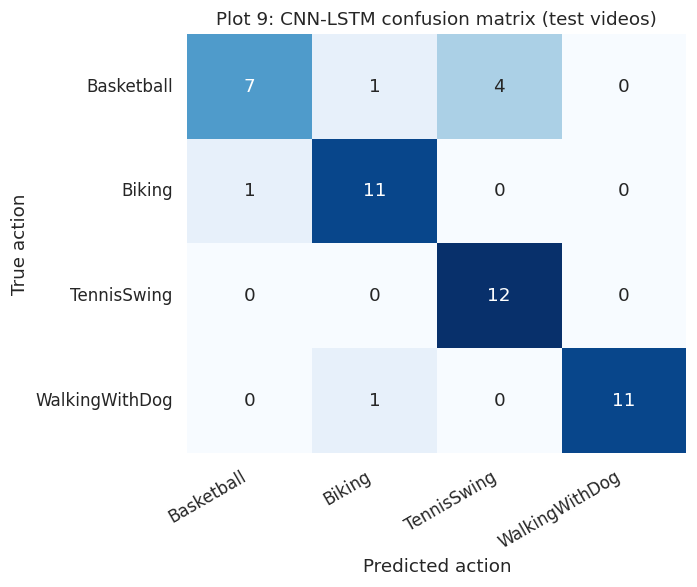

Sample predictions on test videos:

Video           : v_Basketball_g01_c01.avi
Predicted class : TennisSwing
Actual class    : Basketball
Confidence      : 0.92

Video           : v_Basketball_g01_c03.avi
Predicted class : TennisSwing
Actual class    : Basketball
Confidence      : 0.96

Video           : v_Basketball_g01_c05.avi
Predicted class : TennisSwing
Actual class    : Basketball
Confidence      : 0.91

Video           : v_Basketball_g01_c07.avi
Predicted class : TennisSwing
Actual class    : Basketball
Confidence      : 0.67

Video           : v_Basketball_g02_c02.avi
Predicted class : Basketball
Actual class    : Basketball
Confidence      : 0.80

Video           : v_Basketball_g02_c04.avi
Predicted class : Basketball
Actual class    : Basketball
Confidence      : 0.58



In [ ]:
# Plot 8: training / validation curves of the selected model
hv = video_res[best_v]["history"]; ep = np.arange(1, len(hv["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, np.array(hv["accuracy"]) * 100, label="Training accuracy"); axes[0].plot(ep, np.array(hv["val_accuracy"]) * 100, label="Validation accuracy")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy (%)"); axes[0].legend(); axes[0].set_title("Accuracy")
axes[1].plot(ep, hv["loss"], label="Training loss"); axes[1].plot(ep, hv["val_loss"], label="Validation loss")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend(); axes[1].set_title("Loss")
fig.suptitle(f"Plot 8: CNN-{best_v} training and validation curves", y=1.02)
save_show("plot8_video_curves.png")

# Plot 9: confusion matrix on the test videos
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(video_res[best_v]["cm"], annot=True, fmt="d", cmap="Blues", xticklabels=VIDEO_CLASSES, yticklabels=VIDEO_CLASSES, cbar=False)
plt.xlabel("Predicted action"); plt.ylabel("True action"); plt.title(f"Plot 9: CNN-{best_v} confusion matrix (test videos)")
plt.xticks(rotation=30, ha="right")
save_show("plot9_video_confusion.png")

# Expected output format: class + confidence come from the trained model's softmax (never typed by hand)
prob = video_res[best_v]["prob"]
print("Sample predictions on test videos:\n")
for i in range(min(6, len(prob))):
    print(f"Video           : {os.path.basename(test_paths[i])}")
    print(f"Predicted class : {VIDEO_CLASSES[prob[i].argmax()]}")
    print(f"Actual class    : {VIDEO_CLASSES[yv['test'][i]]}")
    print(f"Confidence      : {prob[i].max():.2f}\n")

In [ ]:
hv = video_res[best_v]; cmv = hv["cm"]
support = cmv.sum(axis=1); rec_v = cmv.diagonal() / np.maximum(support, 1)
wrong = [(VIDEO_CLASSES[i], VIDEO_CLASSES[j], int(cmv[i, j])) for i in range(NV) for j in range(NV) if i != j and cmv[i, j] > 0]
wrong.sort(key=lambda t: -t[2])
d8 = diagnose(hv["history"])
inference("Video: training curves and class-level results (Plots 8 and 9)",
          what=f"Training/validation accuracy and loss of CNN-{best_v} on frozen MobileNetV2 features, and the test-video confusion matrix ({int(support.sum())} test videos, {NV} classes).",
          trend=f"Final training / validation accuracy = {d8['final_train_acc']:.1f}% / {d8['final_val_acc']:.1f}% (gap {d8['gap']:+.1f} points). Test accuracy = {hv['acc']*100:.1f}%, macro F1 = {hv['f1']*100:.1f}%. Best class: {VIDEO_CLASSES[int(rec_v.argmax())]} ({rec_v.max()*100:.0f}% recall); weakest: {VIDEO_CLASSES[int(rec_v.argmin())]} ({rec_v.min()*100:.0f}%). "
                + ("Most frequent confusion: " + f"{wrong[0][0]} predicted as {wrong[0][1]} ({wrong[0][2]} videos)." if wrong else "No test video was misclassified."),
          why="Each class has a distinctive appearance (court and ball, bicycle, racket, dog on a lead), which a pretrained CNN encodes well, so a small LSTM/GRU on top is enough. With only a few dozen videos per class, the test set is tiny: one video changes accuracy by several points, so treat the numbers as indicative.",
          conclusion="The CNN-recurrent pipeline can recognise actions from just 10 frames per video, and the confusion matrix shows which actions share visual/temporal cues.")

INFERENCE - Video: training curves and class-level results (Plots 8 and 9)
1. What the plot shows: Training/validation accuracy and loss of CNN-LSTM on frozen MobileNetV2 features,
     and the test-video confusion matrix (48 test videos, 4 classes).
2. Trend observed: Final training / validation accuracy = 100.0% / 87.5% (gap +12.5 points). Test
     accuracy = 85.4%, macro F1 = 84.8%. Best class: TennisSwing (100% recall); weakest: Basketball
     (58%). Most frequent confusion: Basketball predicted as TennisSwing (4 videos).
3. Why it may occur: Each class has a distinctive appearance (court and ball, bicycle, racket, dog on a
     lead), which a pretrained CNN encodes well, so a small LSTM/GRU on top is enough. With only a few
     dozen videos per class, the test set is tiny: one video changes accuracy by several points, so treat
     the numbers as indicative.
4. Conclusion: The CNN-recurrent pipeline can recognise actions from just 10 frames per video, and the
     confusion mat

**Inference: role of the CNN in video understanding.** The frozen CNN looks at **one frame at a time** and captures *spatial* information: objects, shapes, textures, scene layout (a ball and hoop, a bicycle, a racket, grass). It turns each 224×224×3 frame (150,528 numbers) into a compact D-dimensional descriptor, so the recurrent network works with 10×D numbers instead of raw pixels. It has no notion of time.

**Inference: role of the recurrent model in temporal modelling.** The LSTM/GRU reads the 10 feature vectors **in order** and learns *how the content changes over time* (motion, the sequence of events, repeated patterns). Its hidden state summarises the whole video, and only that summary goes to the softmax classifier. That is why frames are arranged as a sequence `(10, D)`: each frame's feature vector is one time step.

# Sections 22–24 — Sequence-to-sequence learning (reversal task)

Synthetic task: input `[1, 4, 7, 2]` → output `[2, 7, 4, 1]`. Symbols are integers 1–9 and sequences have length 4, so there are 9⁴ = 6561 possible sequences. **All 6561 are generated once and split 70/15/15 without overlap**, so no test sequence was seen in training.

**Architecture:** Embedding → **Encoder LSTM** (its final states `h, c` are the *context*) → **Decoder LSTM** initialised with that context → Dense softmax over the vocabulary. Token `0` is a special START token.

**Teacher forcing:** while training, the decoder input is the *true* target shifted right, `[START, 2, 7, 4]`, and it must predict `[2, 7, 4, 1]`. At test time there is no ground truth, so the decoder feeds **its own previous prediction** back in (greedy decoding). All reported accuracies below use this real test-time decoding, which is stricter than the teacher-forced numbers.

In [ ]:
S2S_VOCAB, S2S_UNITS, S2S_EMB, S2S_BATCH = 10, 128, 32, 64        # token 0 = START, tokens 1..9 = data symbols
S2S_EPOCHS = 5 if QUICK_TEST else 60

def make_s2s_data(in_len, target_fn, max_n=8000, seed=SEED):
    rng = np.random.default_rng(seed)
    if (S2S_VOCAB - 1) ** in_len <= max_n:                                    # small space: use every unique sequence
        seqs = np.array(list(itertools.product(range(1, S2S_VOCAB), repeat=in_len)))
    else:                                                                     # large space: sample unique sequences
        seen = set()
        while len(seen) < max_n: seen.add(tuple(int(v) for v in rng.integers(1, S2S_VOCAB, size=in_len)))
        seqs = np.array(sorted(seen))
    rng.shuffle(seqs)
    tgt = target_fn(seqs)
    n = len(seqs); n_tr, n_va = int(.70 * n), int(.15 * n)
    parts = {"train": slice(0, n_tr), "val": slice(n_tr, n_tr + n_va), "test": slice(n_tr + n_va, n)}
    data = {}
    for k, sl in parts.items():
        src, tg = seqs[sl], tgt[sl]
        dec_in = np.concatenate([np.zeros((len(tg), 1), dtype=int), tg[:, :-1]], axis=1)      # START + shifted target
        data[k] = (src.astype("int32"), dec_in.astype("int32"), tg.astype("int32"))
    return data

def build_s2s(units=S2S_UNITS, emb=S2S_EMB):
    enc_in = keras.Input(shape=(None,), dtype="int32", name="encoder_input")
    enc_x = layers.Embedding(S2S_VOCAB, emb, name="enc_embedding")(enc_in)
    _, h, c = layers.LSTM(units, return_state=True, name="encoder_lstm")(enc_x)          # context = (h, c)
    dec_in = keras.Input(shape=(None,), dtype="int32", name="decoder_input")
    dec_emb = layers.Embedding(S2S_VOCAB, emb, name="dec_embedding")
    dec_lstm = layers.LSTM(units, return_sequences=True, return_state=True, name="decoder_lstm")
    dec_out = layers.Dense(S2S_VOCAB, activation="softmax", name="decoder_output")
    d, _, _ = dec_lstm(dec_emb(dec_in), initial_state=[h, c])
    train_model = keras.Model([enc_in, dec_in], dec_out(d), name="seq2seq_train")          # used with teacher forcing
    enc_model = keras.Model(enc_in, [h, c], name="encoder")                                # inference: encoder
    h_in, c_in = keras.Input(shape=(units,)), keras.Input(shape=(units,))
    d2, h2, c2 = dec_lstm(dec_emb(dec_in), initial_state=[h_in, c_in])
    dec_model = keras.Model([dec_in, h_in, c_in], [dec_out(d2), h2, c2], name="decoder_step")   # inference: one step
    return train_model, enc_model, dec_model

def greedy_decode(enc_model, dec_model, src, out_len):
    h, c = enc_model.predict(src, verbose=0)
    tok = np.zeros((len(src), 1), dtype="int32")                                # START token
    outs = []
    for _ in range(out_len):
        probs, h, c = dec_model.predict([tok, h, c], verbose=0)
        tok = probs[:, -1, :].argmax(-1).reshape(-1, 1).astype("int32")         # feed own prediction back in
        outs.append(tok)
    return np.concatenate(outs, axis=1)

def run_seq2seq(in_len, target_fn, epochs=S2S_EPOCHS):
    set_seed()
    data = make_s2s_data(in_len, target_fn)
    tm, em, dm = build_s2s()
    tm.compile(optimizer=keras.optimizers.Adam(LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = tm.fit([data["train"][0], data["train"][1]], data["train"][2],
               validation_data=([data["val"][0], data["val"][1]], data["val"][2]),
               epochs=epochs, batch_size=S2S_BATCH, verbose=0, callbacks=[EpochPrinter(every=10)])
    tt = time.time() - t0
    src, _, tgt = data["test"]
    pred = greedy_decode(em, dm, src, tgt.shape[1])
    tok_acc, seq_acc = (pred == tgt).mean(), (pred == tgt).all(axis=1).mean()
    return dict(model=tm, enc=em, dec=dm, history=h.history, time=tt, data=data, pred=pred, tok_acc=tok_acc, seq_acc=seq_acc,
                params=int(sum(np.prod(w.shape) for w in tm.trainable_weights)),
                train_loss=h.history["loss"][-1], val_loss=h.history["val_loss"][-1])

print("Building the reversal dataset and training the encoder-decoder ...")
s2s = run_seq2seq(4, lambda s: s[:, ::-1])
for k in ["train", "val", "test"]:
    print(f"{k:5s}: {s2s['data'][k][0].shape[0]} sequences")
s2s["model"].summary()
print(f"Training time: {s2s['time']:.1f} s")

Building the reversal dataset and training the encoder-decoder ...
   epoch 01 | loss 1.9227  acc 0.2798 | val_loss 1.4110  val_acc 0.4118
   epoch 10 | loss 0.0070  acc 1.0000 | val_loss 0.0068  val_acc 1.0000
   epoch 20 | loss 0.0015  acc 1.0000 | val_loss 0.0016  val_acc 1.0000
   epoch 30 | loss 0.0006  acc 1.0000 | val_loss 0.0007  val_acc 1.0000
   epoch 40 | loss 0.0003  acc 1.0000 | val_loss 0.0004  val_acc 1.0000
   epoch 50 | loss 0.0002  acc 1.0000 | val_loss 0.0002  val_acc 1.0000


   epoch 60 | loss 0.0001  acc 1.0000 | val_loss 0.0001  val_acc 1.0000
train: 4592 sequences
val  : 984 sequences
test : 985 sequences


Model: "seq2seq_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_embedding       │ (None, None, 32)  │        320 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_embedding       │ (None, None, 32)  │        320 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 128),     │     82,432 │ enc_embedding[0]… │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │     82,432 │ dec_embedding[0]… │
│                     │ 128), (None,      │            │ encoder_lstm[0][… │
│                     │ 128), (None,      │            │ encoder_lstm[0][… │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, None, 10)  │      1,290 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 500,384 (1.91 MB)

 Trainable params: 166,794 (651.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 333,590 (1.27 MB)

Training time: 42.1 s


### Section 23 — Test examples (input → predicted output)

In [ ]:
src, _, tgt = s2s["data"]["test"]; pred = s2s["pred"]
show = pd.DataFrame({"Sample": range(1, 11),
                     "Input Sequence": [list(map(int, r)) for r in src[:10]],
                     "Expected Output": [list(map(int, r)) for r in tgt[:10]],
                     "Predicted Output": [list(map(int, r)) for r in pred[:10]],
                     "Correct?": ["yes" if (a == b).all() else "NO" for a, b in zip(pred[:10], tgt[:10])]}).set_index("Sample")
display(show)
print("Example format from the brief: Input [3, 8, 1, 5] -> expected [5, 1, 8, 3]")

,Input Sequence,Expected Output,Predicted Output,Correct?
Sample,,,,
1,"[3, 1, 8, 2]","[2, 8, 1, 3]","[2, 8, 1, 3]",yes
2,"[3, 7, 4, 4]","[4, 4, 7, 3]","[4, 4, 7, 3]",yes
3,"[4, 3, 3, 5]","[5, 3, 3, 4]","[5, 3, 3, 4]",yes
4,"[5, 2, 6, 6]","[6, 6, 2, 5]","[6, 6, 2, 5]",yes
5,"[2, 3, 9, 6]","[6, 9, 3, 2]","[6, 9, 3, 2]",yes
6,"[9, 5, 5, 4]","[4, 5, 5, 9]","[4, 5, 5, 9]",yes
7,"[2, 3, 9, 8]","[8, 9, 3, 2]","[8, 9, 3, 2]",yes
8,"[7, 5, 6, 7]","[7, 6, 5, 7]","[7, 6, 5, 7]",yes
9,"[3, 5, 4, 1]","[1, 4, 5, 3]","[1, 4, 5, 3]",yes


Example format from the brief: Input [3, 8, 1, 5] -> expected [5, 1, 8, 3]


### Section 24 — Evaluation: token accuracy, sequence accuracy, training loss, validation loss

,Value
Token accuracy (%),100.0000
Sequence accuracy (%),100.0000
Final training loss,0.0001
Final validation loss,0.0001
Parameters,166794.0000
Training time (s),42.1096


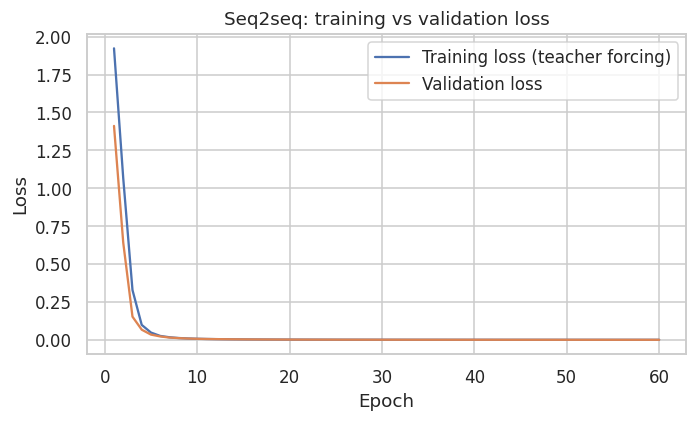

Token accuracy by output position: {'pos 1': 100.0, 'pos 2': 100.0, 'pos 3': 100.0, 'pos 4': 100.0}
INFERENCE - Difference between token accuracy and sequence accuracy (seq2seq)
1. What the plot shows: Test-set accuracy of the encoder-decoder on the reversal task, counted per token
     and per whole sequence (985 test sequences of length 4).
2. Trend observed: Token accuracy = 100.00%, sequence accuracy = 100.00%. If token errors were
     independent, sequence accuracy would be about token_acc^4 = 100.00%.
3. Why it may occur: A sequence counts as correct only if all 4 tokens are correct, so a single wrong
     token spoils the whole sequence. Errors also compound because the decoder feeds its own previous
     prediction into the next step. With token accuracy p, roughly p^4 of the sequences are fully correct
     (for example 0.95^4 = 0.81), so sequence accuracy is always at most token accuracy and drops faster
     for longer sequences.
4. Conclusion: Sequence accuracy is the stri

In [ ]:
s2s_table = pd.DataFrame({"Value": [s2s["tok_acc"] * 100, s2s["seq_acc"] * 100, s2s["train_loss"], s2s["val_loss"], s2s["params"], s2s["time"]]},
                         index=["Token accuracy (%)", "Sequence accuracy (%)", "Final training loss", "Final validation loss", "Parameters", "Training time (s)"])
display(s2s_table)
s2s_table.to_csv(os.path.join(FIG_DIR, "table_seq2seq.csv"))

h = s2s["history"]; ep = np.arange(1, len(h["loss"]) + 1)
plt.figure(figsize=(6.5, 4))
plt.plot(ep, h["loss"], label="Training loss (teacher forcing)"); plt.plot(ep, h["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Seq2seq: training vs validation loss"); plt.legend()
save_show("seq2seq_loss.png")

pos_acc = (pred == tgt).mean(axis=0) * 100
print("Token accuracy by output position:", {f"pos {i+1}": round(float(a), 2) for i, a in enumerate(pos_acc)})

L = tgt.shape[1]; exp_seq = (s2s["tok_acc"] ** L) * 100
inference("Difference between token accuracy and sequence accuracy (seq2seq)",
          what=f"Test-set accuracy of the encoder-decoder on the reversal task, counted per token and per whole sequence ({len(tgt)} test sequences of length {L}).",
          trend=f"Token accuracy = {s2s['tok_acc']*100:.2f}%, sequence accuracy = {s2s['seq_acc']*100:.2f}%. If token errors were independent, sequence accuracy would be about token_acc^{L} = {exp_seq:.2f}%.",
          why=f"A sequence counts as correct only if all {L} tokens are correct, so a single wrong token spoils the whole sequence. Errors also compound because the decoder feeds its own previous prediction into the next step. With token accuracy p, roughly p^{L} of the sequences are fully correct (for example 0.95^4 = 0.81), so sequence accuracy is always at most token accuracy and drops faster for longer sequences.",
          conclusion="Sequence accuracy is the stricter measure for seq2seq tasks; token accuracy can look high even when many complete outputs are wrong."
          + (" In this run the two numbers are close because the model is almost perfect on every token; the gap opens up as soon as token accuracy drops (for example 90% token accuracy over 4 tokens gives only about 66% sequence accuracy)." if (s2s["tok_acc"] - s2s["seq_acc"]) * 100 < 1 else f" Here the gap is {(s2s['tok_acc'] - s2s['seq_acc']) * 100:.1f} points."))

# Section 25 — Consolidated results

In [ ]:
rows = {m: [results[m]["acc"] * 100, results[m]["precision"] * 100, results[m]["recall"] * 100, results[m]["f1"] * 100, results[m]["params"]] for m in names}
rows[f"CNN-{best_v}"] = [video_res[best_v]["acc"] * 100, video_res[best_v]["precision"] * 100, video_res[best_v]["recall"] * 100,
                        video_res[best_v]["f1"] * 100, video_res[best_v]["params"]]
consolidated = pd.DataFrame(rows, index=["Accuracy (%)", "Precision (%)", "Recall (%)", "F1 (%)", "Parameters"]).T
consolidated.index.name = "Model"
display(consolidated)
consolidated.to_csv(os.path.join(FIG_DIR, "table_section25_consolidated.csv"))
print("Precision / Recall / F1 are macro-averaged. HAR rows: 6-class activity test set. CNN row: video test set "
      f"({NV} classes; parameters of the recurrent classifier only, the frozen MobileNetV2 is not counted).\n")

print("Sequence-to-sequence task (separate table):")
display(s2s_table)

,Accuracy (%),Precision (%),Recall (%),F1 (%),Parameters
Model,,,,,
RNN,84.1667,84.5164,84.1667,84.2334,1974.0
LSTM,93.0556,93.2126,93.0556,93.0183,6006.0
GRU,95.5556,95.7768,95.5556,95.5357,4758.0
CNN-LSTM,85.4167,86.7788,85.4167,84.8416,168196.0


Precision / Recall / F1 are macro-averaged. HAR rows: 6-class activity test set. CNN row: video test set (4 classes; parameters of the recurrent classifier only, the frozen MobileNetV2 is not counted).

Sequence-to-sequence task (separate table):


,Value
Token accuracy (%),100.0000
Sequence accuracy (%),100.0000
Final training loss,0.0001
Final validation loss,0.0001
Parameters,166794.0000
Training time (s),42.1096


# Section 26 — Required inferences (checklist)

Each major plot already printed a 4-part inference (what it shows / trend / why / conclusion) built from your own numbers. Where each mandatory one lives:

| # | Mandatory inference | Where |
|---|---|---|
| 1 | Temporal pattern in the sensor signals | Section 6, after Plot 1 |
| 2 | Convergence of RNN | Section 13 |
| 3 | Convergence of LSTM | Section 13 |
| 4 | Convergence of GRU | Section 13 |
| 5 | Overfitting / underfitting evidence | Section 13 (diagnostic table + verdict lines) |
| 6 | Activity-wise errors from the confusion matrix | Section 15 |
| 7 | Effect of sequence length | Section 17 |
| 8 | Parameter and computational differences (RNN/LSTM/GRU) | Section 16 (after Plot 5) |
| 9 | Role of the CNN in video understanding | Section 21 (markdown after Plot 9) |
| 10 | Role of the recurrent model in temporal modelling | Section 21 (markdown after Plot 9) |
| 11 | Token accuracy vs sequence accuracy | Section 24 |

**Tip for your report:** the printed inferences are a data-driven first draft. Copy the numbers, then rewrite the sentences in your own words and check them against the plots you actually see (for example, confirm an "overfitting" verdict visually).

# Section 27 — Discussion questions (short answers)

1. **What is a recurrent neural network?** A network with a loop: it processes a sequence one step at a time and carries a hidden state from step to step, reusing the same weights at every step.
2. **What does the hidden state represent?** A compressed running summary of everything the network has seen so far in the sequence. It is the network's memory at time *t*.
3. **Why is sequence order important?** The meaning lives in the order. The same values in a different order give a different pattern (a walking rhythm shuffled becomes noise; "dog bites man" is not "man bites dog").
4. **Feed-forward network vs RNN?** A feed-forward network takes a fixed-size input, has no memory and treats every input independently. An RNN has a recurrent connection, shares weights across time and can process variable-length ordered data using its state.
5. **What is Backpropagation Through Time?** Unroll the RNN over the T steps, compute the loss, and back-propagate through every step. Because weights are shared, the weight gradient is the sum of the contributions from all time steps.
6. **Why can gradients vanish during BPTT?** The gradient to an early step is a product of many Jacobians, each containing the tanh derivative (≤ 1) and $W_h$. If those factors are below 1, the product shrinks exponentially with the number of steps.
7. **Why can gradients explode?** If the factors are above 1 (large $W_h$), the product grows exponentially, which gives huge updates or NaNs. Gradient clipping is the usual fix.
8. **What are long-term dependencies?** Cases where the output at one step depends on an input many steps earlier (a word 50 tokens back, a gesture that started long ago). Plain RNNs struggle with them.
9. **What is the role of the LSTM cell state?** It is a separate long-term memory line updated additively ($C_t = f_t C_{t-1} + i_t \tilde C_t$), so information and gradients can travel across many steps with little decay.
10. **Forget, input and output gates?** Forget gate: how much of the old cell state to keep. Input gate: how much of the new candidate to write. Output gate: how much of the cell state to reveal as the hidden state $h_t$.
11. **Reset and update gates in GRU?** Update gate $z_t$: how much of the old state to keep versus replace with the new candidate. Reset gate $r_t$: how much of the past to use when computing the candidate.
12. **Compare LSTM and GRU.** LSTM has three gates plus a cell state (more parameters, slower per step). GRU has two gates and no separate cell (about 25% fewer parameters in a same-size layer, faster). Accuracy is often similar; LSTM can be better on very long dependencies.
13. **Why does GRU use a simpler gating mechanism?** It merges the forget and input gates into one update gate ($z_t$ and $1-z_t$) and merges cell and hidden state, so there is less to learn and compute while keeping the gradient-friendly additive update.
14. **Why compare with the same settings?** For a controlled experiment. If data, optimizer, batch size or split differed, we could not tell whether a difference came from the architecture or from those other choices.
15. **What does the confusion matrix reveal that accuracy does not?** Which classes are recognised well, which are confused with which, and whether errors are concentrated in one class, so one accuracy number cannot show that.
16. **Why report macro F1?** It averages the per-class F1 with equal weight, so a poorly recognised class lowers the score even if it is small; overall accuracy can be dominated by large classes.
17. **What is the significance of sequence length?** It sets how much temporal context the model sees. Too short and the pattern is cut off; longer gives more context but costs more computation and makes BPTT cross more steps.
18. **Why can a CNN be a feature extractor for video?** A CNN pretrained on ImageNet has learned general visual features, so its pooled output describes each frame compactly without training from scratch.
19. **What does the CNN extract?** Spatial information within a single frame: objects, shapes, textures, scene layout. No motion.
20. **What does the recurrent network learn?** Temporal information: how the frame features change across the 10 frames (motion, order of events).
21. **Why arrange CNN features as a sequence?** Frames are ordered in time and the LSTM/GRU expects input of shape (T, features). Each frame's feature vector becomes one time step.
22. **Encoder and decoder in seq2seq?** The encoder reads the whole input sequence and compresses it into a context (its final states). The decoder starts from that context and generates the output one element at a time.
23. **What is teacher forcing?** During training the decoder is fed the true previous token rather than its own prediction. It speeds up and stabilises training, but at test time the model must use its own predictions (exposure bias).
24. **Token accuracy vs sequence accuracy?** Token accuracy = correct tokens / total tokens. Sequence accuracy = fully correct sequences / total sequences. The second is stricter.
25. **Why keep the test set untouched during model selection?** If test results influence any choice (epochs, units, architecture), information leaks and the test score becomes an optimistic estimate of real-world performance.

# Section 28 — Additional exercises

Controlled by `RUN_EXERCISES` in the config cell. Exercises 1–4 retrain models (same protocol as the main experiment). Exercises 5 and 6 reuse earlier results. Exercise 7 trains a new seq2seq model.

=== RNN, 16 units ===
   epoch 01 | loss 1.8291  acc 0.2482 | val_loss 1.6539  val_acc 0.4083
   epoch 05 | loss 1.2580  acc 0.4643 | val_loss 1.1781  val_acc 0.4833
   epoch 10 | loss 0.9297  acc 0.6185 | val_loss 0.8676  val_acc 0.6528
   epoch 15 | loss 0.8575  acc 0.6173 | val_loss 0.8159  val_acc 0.6139
   epoch 20 | loss 0.7828  acc 0.6304 | val_loss 0.7560  val_acc 0.6278
   epoch 25 | loss 0.7471  acc 0.6542 | val_loss 0.7181  val_acc 0.6556
   epoch 30 | loss 0.7140  acc 0.6881 | val_loss 0.6965  val_acc 0.6778
=== RNN, 64 units ===
   epoch 01 | loss 1.4875  acc 0.4274 | val_loss 1.2215  val_acc 0.5194
   epoch 05 | loss 0.9705  acc 0.6369 | val_loss 1.0368  val_acc 0.5750
   epoch 10 | loss 0.5871  acc 0.7554 | val_loss 0.5735  val_acc 0.7528
   epoch 15 | loss 0.4755  acc 0.8155 | val_loss 0.4742  val_acc 0.8000
   epoch 20 | loss 0.3855  acc 0.8524 | val_loss 0.4081  val_acc 0.8583
   epoch 25 | loss 0.3818  acc 0.8655 | val_loss 0.4355  val_acc 0.8278
   epoch 30 | loss 0

,Model,Units,Accuracy (%),Macro F1 (%),Parameters,Training time (s)
0,RNN,16,68.3333,68.0273,790,24.0943
1,RNN,32,84.1667,84.2334,1974,24.4303
2,RNN,64,79.1667,78.8242,5878,24.3654
3,LSTM,16,93.3333,93.3160,2038,19.4974
4,LSTM,32,93.0556,93.0183,6006,22.8452
5,LSTM,64,95.2778,95.2467,20086,18.8343
6,GRU,16,94.4444,94.4411,1670,19.2947
7,GRU,32,95.5556,95.5357,4758,20.2839
8,GRU,64,95.2778,95.2385,15542,18.4404


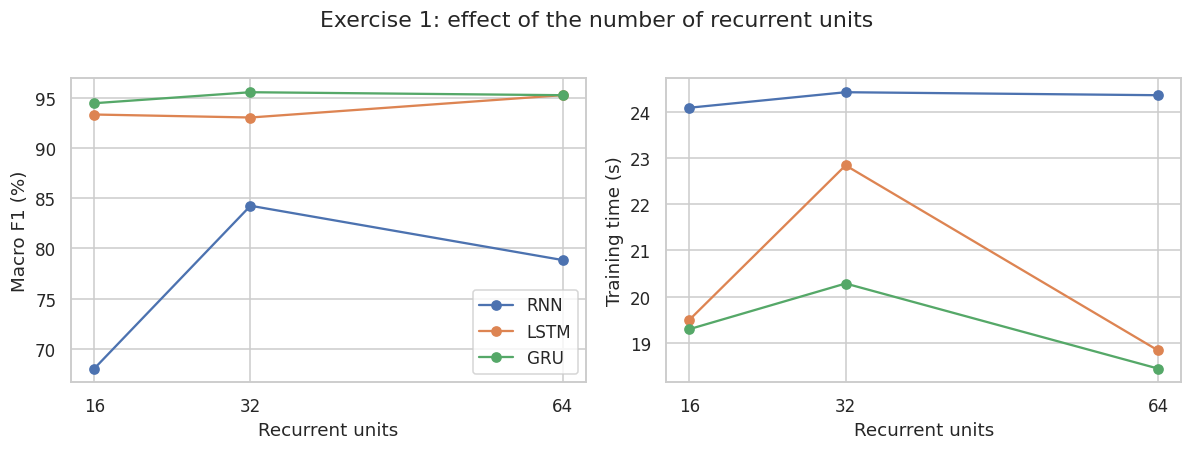

In [ ]:
# Exercise 1: change the recurrent units to 16 and 64 (32 = main experiment) -> accuracy, F1, parameters, time
if RUN_EXERCISES:
    ex1 = []
    for m in names:
        for u in [16, 32, 64]:
            if u == UNITS:
                r = results[m]
            else:
                print(f"=== {m}, {u} units ===")
                r = train_and_eval(m, X_train, y_train, X_val, y_val, X_test, y_test, units=u)
            ex1.append(dict(Model=m, Units=u, **{"Accuracy (%)": r["acc"] * 100, "Macro F1 (%)": r["f1"] * 100,
                                                 "Parameters": r["params"], "Training time (s)": r["time"]}))
    ex1 = pd.DataFrame(ex1)
    display(ex1)
    ex1.to_csv(os.path.join(FIG_DIR, "table_ex1_units.csv"), index=False)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for m in names:
        d = ex1[ex1.Model == m]
        axes[0].plot(d.Units, d["Macro F1 (%)"], marker="o", label=m); axes[1].plot(d.Units, d["Training time (s)"], marker="o", label=m)
    axes[0].set_xlabel("Recurrent units"); axes[0].set_ylabel("Macro F1 (%)"); axes[0].legend(); axes[0].set_xticks([16, 32, 64])
    axes[1].set_xlabel("Recurrent units"); axes[1].set_ylabel("Training time (s)"); axes[1].set_xticks([16, 32, 64])
    fig.suptitle("Exercise 1: effect of the number of recurrent units", y=1.02)
    save_show("ex1_units.png")

In [ ]:
# Exercise 2: GRU vs LSTM with the same number of units (uses the results of Exercise 1)
if RUN_EXERCISES:
    piv = ex1[ex1.Model.isin(["LSTM", "GRU"])].pivot(index="Units", columns="Model", values=["Macro F1 (%)", "Parameters", "Training time (s)"])
    display(piv)
    for u in [16, 32, 64]:
        l, g = ex1[(ex1.Model == "LSTM") & (ex1.Units == u)].iloc[0], ex1[(ex1.Model == "GRU") & (ex1.Units == u)].iloc[0]
        print(f"{u:2d} units: GRU has {g.Parameters/l.Parameters*100:.0f}% of the LSTM parameters, "
              f"F1 difference (GRU - LSTM) = {g['Macro F1 (%)'] - l['Macro F1 (%)']:+.2f} points, time ratio GRU/LSTM = {g['Training time (s)']/l['Training time (s)']:.2f}")

Macro F1 (%)          Parameters          Training time (s)         
Model          GRU     LSTM        GRU     LSTM               GRU     LSTM
Units                                                                     
16         94.4411  93.3160     1670.0   2038.0           19.2947  19.4974
32         95.5357  93.0183     4758.0   6006.0           20.2839  22.8452
64         95.2385  95.2467    15542.0  20086.0           18.4404  18.8343

16 units: GRU has 82% of the LSTM parameters, F1 difference (GRU - LSTM) = +1.13 points, time ratio GRU/LSTM = 0.99
32 units: GRU has 79% of the LSTM parameters, F1 difference (GRU - LSTM) = +2.52 points, time ratio GRU/LSTM = 0.89
64 units: GRU has 77% of the LSTM parameters, F1 difference (GRU - LSTM) = -0.01 points, time ratio GRU/LSTM = 0.98


In [ ]:
# Exercise 3: add a second recurrent layer (two stacked layers of 32 units)
if RUN_EXERCISES:
    ex3 = []
    for m in names:
        print(f"=== {m}, 2 stacked layers ===")
        r2 = train_and_eval(m, X_train, y_train, X_val, y_val, X_test, y_test, second_layer=True, name=f"{m}_2layers")
        for tag, r in [("1 layer", results[m]), ("2 layers", r2)]:
            ex3.append({"Model": m, "Layers": tag, "Accuracy (%)": r["acc"] * 100, "Macro F1 (%)": r["f1"] * 100,
                        "Parameters": r["params"], "Training time (s)": r["time"]})
    ex3 = pd.DataFrame(ex3); display(ex3)
    ex3.to_csv(os.path.join(FIG_DIR, "table_ex3_two_layers.csv"), index=False)
    for m in names:
        d = ex3[ex3.Model == m].set_index("Layers")["Macro F1 (%)"]
        print(f"{m}: F1 {d['1 layer']:.2f}% -> {d['2 layers']:.2f}% ({d['2 layers'] - d['1 layer']:+.2f} points) with a second layer")

=== RNN, 2 stacked layers ===
   epoch 01 | loss 1.4866  acc 0.4387 | val_loss 1.1285  val_acc 0.5694
   epoch 05 | loss 0.6420  acc 0.7060 | val_loss 0.6753  val_acc 0.6833
   epoch 10 | loss 0.5611  acc 0.7637 | val_loss 0.5120  val_acc 0.7917
   epoch 15 | loss 0.6552  acc 0.6935 | val_loss 0.6259  val_acc 0.6944
   epoch 20 | loss 0.5044  acc 0.7964 | val_loss 0.5285  val_acc 0.7944
   epoch 25 | loss 0.4340  acc 0.8310 | val_loss 0.4930  val_acc 0.8139
   epoch 30 | loss 0.3648  acc 0.8738 | val_loss 0.3878  val_acc 0.8556
=== LSTM, 2 stacked layers ===
   epoch 01 | loss 1.4885  acc 0.3893 | val_loss 1.1790  val_acc 0.5389
   epoch 05 | loss 0.3119  acc 0.9065 | val_loss 0.2640  val_acc 0.9250
   epoch 10 | loss 0.1238  acc 0.9565 | val_loss 0.1619  val_acc 0.9444
   epoch 15 | loss 0.1031  acc 0.9619 | val_loss 0.1341  val_acc 0.9500
   epoch 20 | loss 0.0974  acc 0.9613 | val_loss 0.1152  val_acc 0.9528
   epoch 25 | loss 0.0904  acc 0.9601 | val_loss 0.1084  val_acc 0.9528
   

,Model,Layers,Accuracy (%),Macro F1 (%),Parameters,Training time (s)
0,RNN,1 layer,84.1667,84.2334,1974,24.4303
1,RNN,2 layers,81.9444,82.1749,4054,38.5405
2,LSTM,1 layer,93.0556,93.0183,6006,22.8452
3,LSTM,2 layers,95.0000,94.9888,14326,28.6951
4,GRU,1 layer,95.5556,95.5357,4758,20.2839
5,GRU,2 layers,95.5556,95.5357,11094,27.2727


RNN: F1 84.23% -> 82.17% (-2.06 points) with a second layer
LSTM: F1 93.02% -> 94.99% (+1.97 points) with a second layer
GRU: F1 95.54% -> 95.54% (+0.00 points) with a second layer


In [ ]:
# Exercise 4: bidirectional LSTM vs unidirectional LSTM
if RUN_EXERCISES:
    print("=== Bidirectional LSTM ===")
    r_bi = train_and_eval("LSTM", X_train, y_train, X_val, y_val, X_test, y_test, bidirectional=True, name="BiLSTM_32u")
    ex4 = pd.DataFrame({"LSTM (uni)": [results["LSTM"]["acc"] * 100, results["LSTM"]["f1"] * 100, results["LSTM"]["params"], results["LSTM"]["time"]],
                        "BiLSTM":     [r_bi["acc"] * 100, r_bi["f1"] * 100, r_bi["params"], r_bi["time"]]},
                       index=["Accuracy (%)", "Macro F1 (%)", "Parameters", "Training time (s)"])
    display(ex4)
    ex4.to_csv(os.path.join(FIG_DIR, "table_ex4_bilstm.csv"))
    print("BiLSTM reads the window forwards and backwards, so it has about twice the recurrent parameters "
          f"({r_bi['params']:,} vs {results['LSTM']['params']:,}) and costs more time.")

=== Bidirectional LSTM ===
   epoch 01 | loss 1.6043  acc 0.3530 | val_loss 1.2812  val_acc 0.5000
   epoch 05 | loss 0.5221  acc 0.7929 | val_loss 0.4524  val_acc 0.8222
   epoch 10 | loss 0.3094  acc 0.8696 | val_loss 0.2649  val_acc 0.8861
   epoch 15 | loss 0.1591  acc 0.9464 | val_loss 0.1623  val_acc 0.9361
   epoch 20 | loss 0.1035  acc 0.9649 | val_loss 0.1341  val_acc 0.9472
   epoch 25 | loss 0.1076  acc 0.9571 | val_loss 0.1217  val_acc 0.9444
   epoch 30 | loss 0.0937  acc 0.9661 | val_loss 0.1214  val_acc 0.9472


,LSTM (uni),BiLSTM
Accuracy (%),93.0556,94.4444
Macro F1 (%),93.0183,94.4389
Parameters,6006.0000,11894.0000
Training time (s),22.8452,29.3879


BiLSTM reads the window forwards and backwards, so it has about twice the recurrent parameters (11,894 vs 6,006) and costs more time.


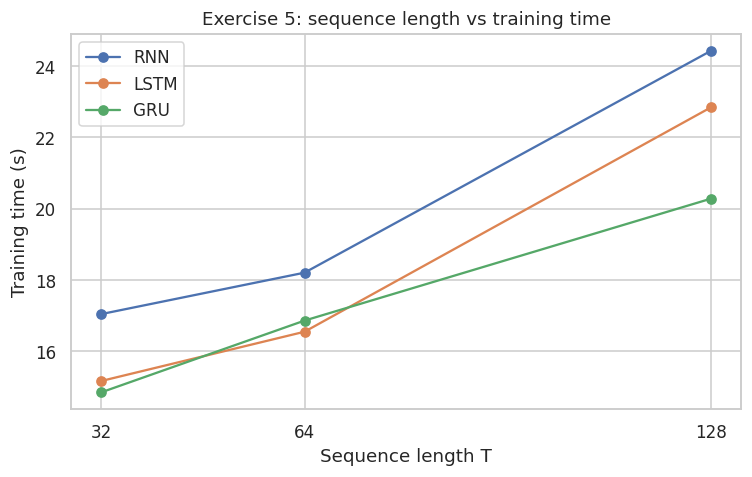

RNN: T=32 -> T=128 (4x longer) increases training time 1.43x
LSTM: T=32 -> T=128 (4x longer) increases training time 1.51x
GRU: T=32 -> T=128 (4x longer) increases training time 1.37x
Recurrent layers process time steps one after another, so cost grows roughly linearly with T (parameters stay the same).


In [ ]:
# Exercise 5: sequence length vs computational cost (uses timings from Section 17)
if RUN_EXERCISES:
    plt.figure(figsize=(7, 4.5))
    for m in names:
        plt.plot(SEQ_LENS, [seq_res[(m, T)]["time"] for T in SEQ_LENS], marker="o", label=m)
    plt.xticks(SEQ_LENS); plt.xlabel("Sequence length T"); plt.ylabel("Training time (s)")
    plt.title("Exercise 5: sequence length vs training time"); plt.legend()
    save_show("ex5_seqlen_cost.png")
    for m in names:
        t32, t128 = seq_res[(m, 32)]["time"], seq_res[(m, 128)]["time"]
        print(f"{m}: T=32 -> T=128 (4x longer) increases training time {t128/t32:.2f}x")
    print("Recurrent layers process time steps one after another, so cost grows roughly linearly with T (parameters stay the same).")

In [ ]:
# Exercise 6: video task, LSTM vs GRU on identical CNN features
ex6 = pd.DataFrame({f"CNN-{c}": [video_res[c]["acc"] * 100, video_res[c]["f1"] * 100, video_res[c]["params"], video_res[c]["time"],
                                 video_res[c]["val_acc"] * 100] for c in ["LSTM", "GRU"]},
                   index=["Test accuracy (%)", "Test macro F1 (%)", "Parameters", "Training time (s)", "Best validation accuracy (%)"])
display(ex6)
ex6.to_csv(os.path.join(FIG_DIR, "table_ex6_video_lstm_vs_gru.csv"))

,CNN-LSTM,CNN-GRU
Test accuracy (%),85.4167,91.6667
Test macro F1 (%),84.8416,91.5898
Parameters,168196.0000,126276.0000
Training time (s),7.7670,6.5617
Best validation accuracy (%),90.0000,90.0000


In [ ]:
# Exercise 7: seq2seq where the output length differs from the input length
# Task: input has 6 symbols, output = the last 3 symbols in reverse order (length 3 != 6)
if RUN_EXERCISES:
    print("Training seq2seq with input length 6 and output length 3 ...")
    s2s7 = run_seq2seq(6, lambda s: s[:, ::-1][:, :3])
    src7, _, tgt7 = s2s7["data"]["test"]
    display(pd.DataFrame({"Input (len 6)": [list(map(int, r)) for r in src7[:8]],
                          "Expected (len 3)": [list(map(int, r)) for r in tgt7[:8]],
                          "Predicted (len 3)": [list(map(int, r)) for r in s2s7["pred"][:8]]}))
    print(f"Token accuracy = {s2s7['tok_acc']*100:.2f}% | Sequence accuracy = {s2s7['seq_acc']*100:.2f}% | "
          f"train loss {s2s7['train_loss']:.4f} | val loss {s2s7['val_loss']:.4f}")
    print("The encoder-decoder handles different lengths because the decoder simply runs for as many steps as the target needs.")

Training seq2seq with input length 6 and output length 3 ...
   epoch 01 | loss 1.8864  acc 0.3047 | val_loss 1.3047  val_acc 0.4808
   epoch 10 | loss 0.0035  acc 1.0000 | val_loss 0.0034  val_acc 1.0000
   epoch 20 | loss 0.0008  acc 1.0000 | val_loss 0.0008  val_acc 1.0000
   epoch 30 | loss 0.0003  acc 1.0000 | val_loss 0.0003  val_acc 1.0000
   epoch 40 | loss 0.0002  acc 1.0000 | val_loss 0.0002  val_acc 1.0000
   epoch 50 | loss 0.0001  acc 1.0000 | val_loss 0.0001  val_acc 1.0000
   epoch 60 | loss 0.0000  acc 1.0000 | val_loss 0.0001  val_acc 1.0000


,Input (len 6),Expected (len 3),Predicted (len 3)
0,"[7, 6, 5, 3, 5, 3]","[3, 5, 3]","[3, 5, 3]"
1,"[9, 1, 7, 3, 1, 3]","[3, 1, 3]","[3, 1, 3]"
2,"[4, 9, 8, 9, 9, 4]","[4, 9, 9]","[4, 9, 9]"
3,"[5, 6, 5, 4, 1, 3]","[3, 1, 4]","[3, 1, 4]"
4,"[6, 3, 4, 3, 4, 4]","[4, 4, 3]","[4, 4, 3]"
5,"[9, 2, 3, 1, 7, 8]","[8, 7, 1]","[8, 7, 1]"
6,"[9, 9, 6, 7, 1, 2]","[2, 1, 7]","[2, 1, 7]"
7,"[7, 6, 2, 5, 9, 4]","[4, 9, 5]","[4, 9, 5]"


Token accuracy = 100.00% | Sequence accuracy = 100.00% | train loss 0.0000 | val loss 0.0001
The encoder-decoder handles different lengths because the decoder simply runs for as many steps as the target needs.


# Section 29 — Expected outcome

You have now run both pipelines and the encoder–decoder formulation:

- **Sequential data → Preprocessing → RNN/LSTM/GRU → Evaluation** (Sections 3–17)
- **Video → Frames → CNN features → LSTM/GRU → Action prediction** (Sections 18–21)
- **Input sequence → Encoder → Context → Decoder → Output sequence** (Sections 22–24)

All numerical values come from your own execution.

# Section 30 — References

1. Ian Goodfellow, Yoshua Bengio and Aaron Courville, *Deep Learning*, MIT Press, 2016.
2. Sepp Hochreiter and Jürgen Schmidhuber, "Long Short-Term Memory," *Neural Computation*, 1997.
3. Kyunghyun Cho et al., "Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation," EMNLP, 2014.
4. Anguita et al., "A Public Domain Dataset for Human Activity Recognition Using Smartphones," ESANN, 2013.
5. Khurram Soomro, Amir Roshan Zamir and Mubarak Shah, "UCF101: A Dataset of 101 Human Actions Classes From Videos in the Wild," 2012.
6. TensorFlow Documentation: https://www.tensorflow.org
7. Keras Documentation: https://keras.io

# Export (optional)

Bundles all figures and CSV tables (use them in your Overleaf report).

In [ ]:
zip_path = shutil.make_archive("experiment6_outputs", "zip", FIG_DIR)
print("Created:", zip_path, "|", len(os.listdir(FIG_DIR)), "files in", FIG_DIR)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("(Not running in Colab: find the zip in the working directory.)")

Created: /content/experiment6_outputs.zip | 30 files in figures


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>